In [ ]:
import numpy as np
import pandas as pd
df=pd.read_csv('../data/raw/city_hour.csv')

In [ ]:
# Check missing values in the target columns
print("Missing AQI values:", df["AQI"].isna().sum())
print("Missing AQI_Bucket values:", df["AQI_Bucket"].isna().sum())

# Examine the distribution of AQI categories
print("\nAQI_Bucket distribution:")
print(df["AQI_Bucket"].value_counts(dropna=False))

# Inspect numerical AQI statistics
print("\nAQI summary statistics:")
print(df["AQI"].describe())

Missing AQI values: 129080
Missing AQI_Bucket values: 129080

AQI_Bucket distribution:
AQI_Bucket
Moderate        198991
Satisfactory    189434
NaN             129080
Poor             66654
Very Poor        57455
Good             38611
Severe           27650
Name: count, dtype: int64

AQI summary statistics:
count    578795.000000
mean        166.413500
std         162.112729
min           8.000000
25%          79.000000
50%         116.000000
75%         208.000000
max        3133.000000
Name: AQI, dtype: float64


In [ ]:
import numpy as np
import pandas as pd

# Define the expected category for each numerical AQI value
conditions = [
    df["AQI"].between(0, 50),
    df["AQI"].between(51, 100),
    df["AQI"].between(101, 200),
    df["AQI"].between(201, 300),
    df["AQI"].between(301, 400),
    df["AQI"] > 400
]

categories = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

df["Expected_AQI_Bucket"] = np.select(
    conditions,
    categories,
    default="Invalid_or_Missing"
)

# Identify rows where the recorded and expected categories differ
labelled = df["AQI"].notna() & df["AQI_Bucket"].notna()

mismatches = df.loc[
    labelled
    & (df["AQI_Bucket"] != df["Expected_AQI_Bucket"])
]

print("Rows with both AQI and AQI_Bucket:", labelled.sum())
print("Category mismatches:", len(mismatches))

print("\nMismatch examples:")
print(
    mismatches[
        ["City", "Datetime", "AQI", "AQI_Bucket", "Expected_AQI_Bucket"]
    ].head(20)
)

print("\nAQI values outside the expected 0–500 range:")
print(
    df.loc[
        df["AQI"].notna() & ~df["AQI"].between(0, 500),
        ["City", "Datetime", "AQI", "AQI_Bucket"]
    ].head(20)
)

Rows with both AQI and AQI_Bucket: 578795
Category mismatches: 0

Mismatch examples:
Empty DataFrame
Columns: [City, Datetime, AQI, AQI_Bucket, Expected_AQI_Bucket]
Index: []

AQI values outside the expected 0–500 range:
          City             Datetime     AQI AQI_Bucket
716  Ahmedabad  2015-01-30 21:00:00   953.0     Severe
717  Ahmedabad  2015-01-30 22:00:00   953.0     Severe
718  Ahmedabad  2015-01-30 23:00:00   953.0     Severe
719  Ahmedabad  2015-01-31 00:00:00   953.0     Severe
720  Ahmedabad  2015-01-31 01:00:00   953.0     Severe
721  Ahmedabad  2015-01-31 02:00:00   953.0     Severe
722  Ahmedabad  2015-01-31 03:00:00   953.0     Severe
723  Ahmedabad  2015-01-31 04:00:00   953.0     Severe
724  Ahmedabad  2015-01-31 05:00:00   608.0     Severe
739  Ahmedabad  2015-01-31 20:00:00   518.0     Severe
740  Ahmedabad  2015-01-31 21:00:00   539.0     Severe
741  Ahmedabad  2015-01-31 22:00:00   809.0     Severe
742  Ahmedabad  2015-01-31 23:00:00  1217.0     Severe
743  Ahme

In [ ]:
# Count AQI values outside the expected 0–500 range
below_zero = df["AQI"].notna() & (df["AQI"] < 0)
above_500 = df["AQI"].notna() & (df["AQI"] > 500)

print("AQI values below 0:", below_zero.sum())
print("AQI values above 500:", above_500.sum())

print("\nPercentage of recorded AQI values above 500:")
print(round(above_500.sum() / df["AQI"].notna().sum() * 100, 3), "%")

print("\nMost frequent AQI values above 500:")
print(df.loc[above_500, "AQI"].value_counts().head(15))

print("\nCities with the most AQI values above 500:")
print(df.loc[above_500, "City"].value_counts().head(15))

AQI values below 0: 0
AQI values above 500: 11135

Percentage of recorded AQI values above 500:
1.924 %

Most frequent AQI values above 500:
AQI
507.0    123
516.0    114
510.0    106
508.0    100
504.0     93
620.0     90
537.0     88
503.0     86
501.0     83
524.0     82
528.0     82
538.0     79
511.0     78
506.0     77
532.0     75
Name: count, dtype: int64

Cities with the most AQI values above 500:
City
Ahmedabad     7681
Delhi         1308
Gurugram       596
Patna          569
Lucknow        394
Jorapokhar     153
Hyderabad      140
Talcher        116
Amritsar       100
Guwahati        63
Jaipur          15
Name: count, dtype: int64


In [ ]:
# Summarize AQI values above 500 by city
extreme_aqi = df[df["AQI"] > 500]

city_summary = (
    extreme_aqi.groupby("City")["AQI"]
    .agg(
        count="count",
        minimum="min",
        median="median",
        maximum="max"
    )
    .sort_values("count", ascending=False)
)

print("AQI > 500 records by city:")
print(city_summary.to_string())

print("\nTotal records:", len(extreme_aqi))
print("Cities affected:", extreme_aqi["City"].nunique())

AQI > 500 records by city:
            count  minimum  median  maximum
City                                       
Ahmedabad    7681    501.0   770.0   3133.0
Delhi        1308    501.0   542.0    762.0
Gurugram      596    501.0   551.0    966.0
Patna         569    501.0   538.0    655.0
Lucknow       394    501.0   536.5    761.0
Jorapokhar    153    501.0   563.0    655.0
Hyderabad     140    504.0   546.5    877.0
Talcher       116    501.0   526.0    620.0
Amritsar      100    501.0   755.0   1052.0
Guwahati       63    503.0   867.0   1109.0
Jaipur         15    506.0   534.0    556.0

Total records: 11135
Cities affected: 11


In [ ]:
station_df=pd.read_csv('../data/raw/station_hour.csv')
print("Dataset shape:", station_df.shape)
print("\nColumns:")
print(station_df.columns.tolist())

print("\nFirst 5 rows:")
display(station_df.head())

print("\nData types and non-null counts:")
station_df.info()

C:\Users\hp\AppData\Local\Temp\ipykernel_2532\2698759093.py:1: DtypeWarning: Columns (15: AQI_Bucket) have mixed types. Specify dtype option on import or set low_memory=False.
  station_df=pd.read_csv('../data/raw/station_hour.csv')


Dataset shape: (2589083, 16)

Columns:
['StationId', 'Datetime', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

First 5 rows:


,StationId,Datetime,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,AP001,2017-11-24 17:00:00,60.50,98.00,2.35,30.80,18.25,8.50,0.1,11.85,126.40,0.1,6.10,0.10,NaN,NaN
1,AP001,2017-11-24 18:00:00,65.50,111.25,2.70,24.20,15.07,9.77,0.1,13.17,117.12,0.1,6.25,0.15,NaN,NaN
2,AP001,2017-11-24 19:00:00,80.00,132.00,2.10,25.18,15.15,12.02,0.1,12.08,98.98,0.2,5.98,0.18,NaN,NaN
3,AP001,2017-11-24 20:00:00,81.50,133.25,1.95,16.25,10.23,11.58,0.1,10.47,112.20,0.2,6.72,0.10,NaN,NaN
4,AP001,2017-11-24 21:00:00,75.25,116.00,1.43,17.48,10.43,12.03,0.1,9.12,106.35,0.2,5.75,0.08,NaN,NaN



Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 2589083 entries, 0 to 2589082
Data columns (total 16 columns):
 #   Column      Dtype  
---  ------      -----  
 0   StationId   str    
 1   Datetime    str    
 2   PM2.5       float64
 3   PM10        float64
 4   NO          float64
 5   NO2         float64
 6   NOx         float64
 7   NH3         float64
 8   CO          float64
 9   SO2         float64
 10  O3          float64
 11  Benzene     float64
 12  Toluene     float64
 13  Xylene      float64
 14  AQI         float64
 15  AQI_Bucket  str    
dtypes: float64(13), str(3)
memory usage: 316.1 MB


In [ ]:
# Check whether the expected columns exist
required_columns = [
    "StationId", "Datetime",
    "PM2.5", "PM10", "SO2", "NOx", "NH3", "CO", "O3",
    "AQI"
]

missing_columns = [
    col for col in required_columns
    if col not in station_df.columns
]

print("Missing required columns:", missing_columns)

# Inspect missing values in the relevant columns
available_columns = [
    col for col in required_columns
    if col in station_df.columns
]

print("\nMissing-value counts:")
display(station_df[available_columns].isna().sum())

# Check station and timestamp coverage
if "StationId" in station_df.columns:
    print("\nNumber of stations:", station_df["StationId"].nunique())

if "Datetime" in station_df.columns:
    print("Date range:")
    print(station_df["Datetime"].min(), "to", station_df["Datetime"].max())

Missing required columns: []

Missing-value counts:


StationId          0
Datetime           0
PM2.5         647689
PM10         1119252
SO2           742737
NOx           490808
NH3          1236618
CO            499302
O3            725973
AQI           570190
dtype: int64


Number of stations: 110
Date range:
2015-01-01 01:00:00 to 2020-07-01 00:00:00


In [ ]:
# 1. Check dataset size and duplicate records
print("Total rows:", len(station_df))
print("Exact duplicate rows:", station_df.duplicated().sum())

# 2. Convert Datetime to datetime format
station_df["Datetime"] = pd.to_datetime(
    station_df["Datetime"],
    errors="coerce"
)

print("\nInvalid timestamps:", station_df["Datetime"].isna().sum())

# 3. Check duplicate station-timestamp combinations
duplicate_station_times = station_df.duplicated(
    subset=["StationId", "Datetime"]
).sum()

print("Duplicate StationId-Datetime pairs:", duplicate_station_times)

# 4. Count recorded AQI values
print("\nAQI availability:")
print("Recorded AQI:", station_df["AQI"].notna().sum())
print("Missing AQI:", station_df["AQI"].isna().sum())

# 5. AQI distribution and extreme values
print("\nAQI descriptive statistics:")
display(station_df["AQI"].describe())

print("\nAQI values above 500:")
print((station_df["AQI"] > 500).sum())

# 6. Check hourly continuity for each station
station_df = station_df.sort_values(
    ["StationId", "Datetime"]
).copy()

station_df["time_gap"] = (
    station_df.groupby("StationId")["Datetime"].diff()
)

print("\nTime-gap distribution:")
display(station_df["time_gap"].value_counts().head(10))

print(
    "\nGaps longer than one hour:",
    (station_df["time_gap"] > pd.Timedelta(hours=1)).sum()
)

Total rows: 2589083
Exact duplicate rows: 0

Invalid timestamps: 0
Duplicate StationId-Datetime pairs: 0

AQI availability:
Recorded AQI: 2018893
Missing AQI: 570190

AQI descriptive statistics:


count    2.018893e+06
mean     1.801730e+02
std      1.404095e+02
min      5.000000e+00
25%      8.400000e+01
50%      1.310000e+02
75%      2.590000e+02
max      3.133000e+03
Name: AQI, dtype: float64


AQI values above 500:
43761

Time-gap distribution:


time_gap
0 days 01:00:00    2588973
Name: count, dtype: int64


Gaps longer than one hour: 0


In [ ]:
# Check whether station metadata is already included
print("Available columns:")
print(station_df.columns.tolist())

# Inspect a few rows
display(station_df.head())

# Check the number of observations per station
station_counts = (
    station_df.groupby("StationId")
    .size()
    .sort_values(ascending=False)
)

print("\nObservations per station:")
display(station_counts.describe())

print("\nFive stations with the most observations:")
display(station_counts.head())

print("\nFive stations with the fewest observations:")
display(station_counts.tail())

Available columns:
['StationId', 'Datetime', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket', 'time_gap']


,StationId,Datetime,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket,time_gap
0,AP001,2017-11-24 17:00:00,60.50,98.00,2.35,30.80,18.25,8.50,0.1,11.85,126.40,0.1,6.10,0.10,NaN,NaN,NaT
1,AP001,2017-11-24 18:00:00,65.50,111.25,2.70,24.20,15.07,9.77,0.1,13.17,117.12,0.1,6.25,0.15,NaN,NaN,0 days 01:00:00
2,AP001,2017-11-24 19:00:00,80.00,132.00,2.10,25.18,15.15,12.02,0.1,12.08,98.98,0.2,5.98,0.18,NaN,NaN,0 days 01:00:00
3,AP001,2017-11-24 20:00:00,81.50,133.25,1.95,16.25,10.23,11.58,0.1,10.47,112.20,0.2,6.72,0.10,NaN,NaN,0 days 01:00:00
4,AP001,2017-11-24 21:00:00,75.25,116.00,1.43,17.48,10.43,12.03,0.1,9.12,106.35,0.2,5.75,0.08,NaN,NaN,0 days 01:00:00



Observations per station:


count      110.000000
mean     23537.118182
std      14739.281331
min       2680.000000
25%       9441.250000
50%      21135.000000
75%      33186.500000
max      48192.000000
dtype: float64


Five stations with the most observations:


StationId
DL007    48192
DL033    48192
DL021    48192
DL013    48192
DL008    48192
dtype: int64


Five stations with the fewest observations:


StationId
BR005    2985
BR006    2863
HR013    2817
HR012    2817
MZ001    2680
dtype: int64

In [ ]:
# Check hourly coverage separately for every station

station_coverage = (
    station_df.groupby("StationId")
    .agg(
        first_record=("Datetime", "min"),
        last_record=("Datetime", "max"),
        total_records=("Datetime", "count"),
        unique_timestamps=("Datetime", "nunique")
    )
)

# Expected number of hourly observations within each station's date range
station_coverage["expected_hours"] = (
    (station_coverage["last_record"] - station_coverage["first_record"])
    / pd.Timedelta(hours=1)
    + 1
).astype(int)

station_coverage["missing_hours"] = (
    station_coverage["expected_hours"]
    - station_coverage["unique_timestamps"]
)

print("Stations checked:", len(station_coverage))
print("Stations with missing hours:", 
      (station_coverage["missing_hours"] > 0).sum())

print("\nStations with the most missing hours:")
display(
    station_coverage.sort_values(
        "missing_hours", ascending=False
    ).head(10)
)

Stations checked: 110
Stations with missing hours: 0

Stations with the most missing hours:


,first_record,last_record,total_records,unique_timestamps,expected_hours,missing_hours
StationId,,,,,,
AP001,2017-11-24 17:00:00,2020-07-01,22784,22784,22784,0
AP005,2016-07-01 12:00:00,2020-07-01,35053,35053,35053,0
AS001,2019-02-16 23:00:00,2020-07-01,12002,12002,12002,0
BR005,2020-02-27 16:00:00,2020-07-01,2985,2985,2985,0
BR006,2020-03-03 18:00:00,2020-07-01,2863,2863,2863,0
BR007,2015-06-01 15:00:00,2020-07-01,44554,44554,44554,0
BR008,2019-12-24 18:00:00,2020-07-01,4543,4543,4543,0
BR009,2019-12-24 18:00:00,2020-07-01,4543,4543,4543,0
BR010,2019-12-24 18:00:00,2020-07-01,4543,4543,4543,0


In [ ]:


stations_df=pd.read_csv('../data/raw/stations.csv')

print("Dataset shape:", stations_df.shape)

print("\nColumns:")
print(stations_df.columns.tolist())

print("\nFirst five rows:")
display(stations_df.head())

print("\nMissing values:")
display(stations_df.isna().sum())

Dataset shape: (230, 5)

Columns:
['StationId', 'StationName', 'City', 'State', 'Status']

First five rows:


,StationId,StationName,City,State,Status
0,AP001,"Secretariat, Amaravati - APPCB",Amaravati,Andhra Pradesh,Active
1,AP002,"Anand Kala Kshetram, Rajamahendravaram - APPCB",Rajamahendravaram,Andhra Pradesh,NaN
2,AP003,"Tirumala, Tirupati - APPCB",Tirupati,Andhra Pradesh,NaN
3,AP004,"PWD Grounds, Vijayawada - APPCB",Vijayawada,Andhra Pradesh,NaN
4,AP005,"GVM Corporation, Visakhapatnam - APPCB",Visakhapatnam,Andhra Pradesh,Active



Missing values:


StationId       0
StationName     0
City            0
State           0
Status         97
dtype: int64

In [ ]:
# 1. Check for duplicate station IDs in the metadata
print(
    "Duplicate StationIds in metadata:",
    stations_df["StationId"].duplicated().sum()
)

# 2. Check how many hourly stations have matching metadata
hourly_station_ids = set(station_df["StationId"].unique())
metadata_station_ids = set(stations_df["StationId"].unique())

matched_ids = hourly_station_ids & metadata_station_ids
unmatched_ids = hourly_station_ids - metadata_station_ids

print("\nUnique stations in station_hour:", len(hourly_station_ids))
print("Unique stations in metadata:", len(metadata_station_ids))
print("Matched stations:", len(matched_ids))
print("Unmatched hourly stations:", len(unmatched_ids))

if unmatched_ids:
    print("Unmatched StationIds:", sorted(unmatched_ids))

# 3. Check which cities are represented in the hourly dataset
hourly_metadata = stations_df[
    stations_df["StationId"].isin(hourly_station_ids)
].copy()

print("\nCities represented in station_hour:")
display(
    hourly_metadata.groupby("City")["StationId"]
    .nunique()
    .sort_values(ascending=False)
    .to_frame("number_of_stations")
)

# 4. Check whether any station ID maps to multiple cities
cities_per_station = stations_df.groupby("StationId")["City"].nunique()

print(
    "\nStationIds associated with multiple cities:",
    (cities_per_station > 1).sum()
)

Duplicate StationIds in metadata: 0

Unique stations in station_hour: 110
Unique stations in metadata: 230
Matched stations: 110
Unmatched hourly stations: 0

Cities represented in station_hour:


,number_of_stations
City,
Delhi,38
Bengaluru,10
Mumbai,10
Kolkata,7
Hyderabad,6
Patna,6
Lucknow,5
Gurugram,4
Chennai,4



StationIds associated with multiple cities: 0


In [ ]:
# Select the station metadata we need
station_metadata = stations_df[
    ["StationId", "City", "State"]
].copy()

# Merge city and state into hourly observations
station_aqi_df = station_df.merge(
    station_metadata,
    on="StationId",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Verify the merge
print("Original hourly rows:", len(station_df))
print("Rows after merge:", len(station_aqi_df))

print("\nMetadata merge results:")
print(station_aqi_df["_merge"].value_counts())

# Remove the merge indicator after verification
station_aqi_df.drop(columns="_merge", inplace=True)

print("\nDataset shape:", station_aqi_df.shape)
print("\nSample:")
display(
    station_aqi_df[
        ["StationId", "City", "State", "Datetime",
         "PM2.5", "PM10", "AQI", "AQI_Bucket"]
    ].head()
)

Original hourly rows: 2589083
Rows after merge: 2589083

Metadata merge results:
_merge
both          2589083
left_only           0
right_only          0
Name: count, dtype: int64

Dataset shape: (2589083, 19)

Sample:


,StationId,City,State,Datetime,PM2.5,PM10,AQI,AQI_Bucket
0,AP001,Amaravati,Andhra Pradesh,2017-11-24 17:00:00,60.50,98.00,NaN,NaN
1,AP001,Amaravati,Andhra Pradesh,2017-11-24 18:00:00,65.50,111.25,NaN,NaN
2,AP001,Amaravati,Andhra Pradesh,2017-11-24 19:00:00,80.00,132.00,NaN,NaN
3,AP001,Amaravati,Andhra Pradesh,2017-11-24 20:00:00,81.50,133.25,NaN,NaN
4,AP001,Amaravati,Andhra Pradesh,2017-11-24 21:00:00,75.25,116.00,NaN,NaN


In [ ]:
# Pollutants that use a 24-hour rolling average
average_pollutants = [
    "PM2.5", "PM10", "SO2", "NOx", "NH3"
]

# Pollutants that use an 8-hour rolling maximum
maximum_pollutants = ["CO", "O3"]

# Ensure observations are in chronological order within each station
station_aqi_df = station_aqi_df.sort_values(
    ["StationId", "Datetime"]
).copy()

# Calculate 24-hour rolling averages
for pollutant in average_pollutants:

    station_aqi_df[f"{pollutant}_24h_avg"] = (
        station_aqi_df
        .groupby("StationId")[pollutant]
        .transform(
            lambda s: s.rolling(
                window=24,
                min_periods=16
            ).mean()
        )
    )

# Calculate 8-hour rolling maximums
for pollutant in maximum_pollutants:

    station_aqi_df[f"{pollutant}_8h_max"] = (
        station_aqi_df
        .groupby("StationId")[pollutant]
        .transform(
            lambda s: s.rolling(
                window=8,
                min_periods=1
            ).max()
        )
    )

print("Rolling measurements calculated.")

print("\nFirst five rows:")
display(
    station_aqi_df[
        [
            "StationId",
            "Datetime",
            "PM2.5",
            "PM2.5_24h_avg",
            "PM10",
            "PM10_24h_avg",
            "CO",
            "CO_8h_max",
            "O3",
            "O3_8h_max"
        ]
    ].head()
)

Rolling measurements calculated.

First five rows:


,StationId,Datetime,PM2.5,PM2.5_24h_avg,PM10,PM10_24h_avg,CO,CO_8h_max,O3,O3_8h_max
0,AP001,2017-11-24 17:00:00,60.50,NaN,98.00,NaN,0.1,0.1,126.40,126.4
1,AP001,2017-11-24 18:00:00,65.50,NaN,111.25,NaN,0.1,0.1,117.12,126.4
2,AP001,2017-11-24 19:00:00,80.00,NaN,132.00,NaN,0.1,0.1,98.98,126.4
3,AP001,2017-11-24 20:00:00,81.50,NaN,133.25,NaN,0.1,0.1,112.20,126.4
4,AP001,2017-11-24 21:00:00,75.25,NaN,116.00,NaN,0.1,0.1,106.35,126.4


In [ ]:
rolling_columns = (
    [f"{p}_24h_avg" for p in average_pollutants]
    + [f"{p}_8h_max" for p in maximum_pollutants]
)

print("Available rolling measurements:")
display(
    station_aqi_df[rolling_columns]
    .notna()
    .sum()
    .to_frame("valid_rows")
)

print("\nPercentage available:")
display(
    (
        station_aqi_df[rolling_columns].notna().mean() * 100
    ).round(2).to_frame("availability_percent")
)

Available rolling measurements:


,valid_rows
PM2.5_24h_avg,1930066
PM10_24h_avg,1463183
SO2_24h_avg,1845088
NOx_24h_avg,2087458
NH3_24h_avg,1344862
CO_8h_max,2201453
O3_8h_max,1928356



Percentage available:


,availability_percent
PM2.5_24h_avg,74.55
PM10_24h_avg,56.51
SO2_24h_avg,71.26
NOx_24h_avg,80.63
NH3_24h_avg,51.94
CO_8h_max,85.03
O3_8h_max,74.48


In [ ]:
import numpy as np
import pandas as pd


def get_PM25_subindex(x):
    if pd.isna(x):
        return np.nan
    if x <= 30:
        return x * 50 / 30
    elif x <= 60:
        return 50 + (x - 30) * 50 / 30
    elif x <= 90:
        return 100 + (x - 60) * 100 / 30
    elif x <= 120:
        return 200 + (x - 90) * 100 / 30
    elif x <= 250:
        return 300 + (x - 120) * 100 / 130
    else:
        return 400 + (x - 250) * 100 / 130


def get_PM10_subindex(x):
    if pd.isna(x):
        return np.nan
    if x <= 100:
        return x
    elif x <= 250:
        return 100 + (x - 100) * 100 / 150
    elif x <= 350:
        return 200 + (x - 250)
    elif x <= 430:
        return 300 + (x - 350) * 100 / 80
    else:
        return 400 + (x - 430) * 100 / 80


def get_SO2_subindex(x):
    if pd.isna(x):
        return np.nan
    if x <= 40:
        return x * 50 / 40
    elif x <= 80:
        return 50 + (x - 40) * 50 / 40
    elif x <= 380:
        return 100 + (x - 80) * 100 / 300
    elif x <= 800:
        return 200 + (x - 380) * 100 / 420
    elif x <= 1600:
        return 300 + (x - 800) * 100 / 800
    else:
        return 400 + (x - 1600) * 100 / 800


def get_NOx_subindex(x):
    if pd.isna(x):
        return np.nan
    if x <= 40:
        return x * 50 / 40
    elif x <= 80:
        return 50 + (x - 40) * 50 / 40
    elif x <= 180:
        return 100 + (x - 80)
    elif x <= 280:
        return 200 + (x - 180)
    elif x <= 400:
        return 300 + (x - 280) * 100 / 120
    else:
        return 400 + (x - 400) * 100 / 120


def get_NH3_subindex(x):
    if pd.isna(x):
        return np.nan
    if x <= 200:
        return x * 50 / 200
    elif x <= 400:
        return 50 + (x - 200) * 50 / 200
    elif x <= 800:
        return 100 + (x - 400) * 100 / 400
    elif x <= 1200:
        return 200 + (x - 800) * 100 / 400
    elif x <= 1800:
        return 300 + (x - 1200) * 100 / 600
    else:
        return 400 + (x - 1800) * 100 / 600


def get_CO_subindex(x):
    if pd.isna(x):
        return np.nan
    if x <= 1:
        return x * 50
    elif x <= 2:
        return 50 + (x - 1) * 50
    elif x <= 10:
        return 100 + (x - 2) * 100 / 8
    elif x <= 17:
        return 200 + (x - 10) * 100 / 7
    elif x <= 34:
        return 300 + (x - 17) * 100 / 17
    else:
        return 400 + (x - 34) * 100 / 17


def get_O3_subindex(x):
    if pd.isna(x):
        return np.nan
    if x <= 50:
        return x
    elif x <= 100:
        return 50 + (x - 50)
    elif x <= 168:
        return 100 + (x - 100) * 100 / 68
    elif x <= 208:
        return 200 + (x - 168) * 100 / 40
    elif x <= 748:
        return 300 + (x - 208) * 100 / 540
    else:
        return 400 + (x - 748) * 100 / 540

In [ ]:
# Map each rolling measurement to its sub-index function
subindex_config = {
    "PM2.5_24h_avg": ("PM2.5_SubIndex", get_PM25_subindex),
    "PM10_24h_avg": ("PM10_SubIndex", get_PM10_subindex),
    "SO2_24h_avg": ("SO2_SubIndex", get_SO2_subindex),
    "NOx_24h_avg": ("NOx_SubIndex", get_NOx_subindex),
    "NH3_24h_avg": ("NH3_SubIndex", get_NH3_subindex),
    "CO_8h_max": ("CO_SubIndex", get_CO_subindex),
    "O3_8h_max": ("O3_SubIndex", get_O3_subindex),
}

for input_col, (output_col, function) in subindex_config.items():
    station_aqi_df[output_col] = station_aqi_df[input_col].apply(function)

print("Sub-index calculation completed.")

Sub-index calculation completed.


In [ ]:
subindex_columns = [
    "PM2.5_SubIndex",
    "PM10_SubIndex",
    "SO2_SubIndex",
    "NOx_SubIndex",
    "NH3_SubIndex",
    "CO_SubIndex",
    "O3_SubIndex",
]

# Check the number and percentage of available sub-indexes
subindex_summary = pd.DataFrame({
    "Available": station_aqi_df[subindex_columns].notna().sum(),
    "Missing": station_aqi_df[subindex_columns].isna().sum(),
    "Min": station_aqi_df[subindex_columns].min(),
    "Median": station_aqi_df[subindex_columns].median(),
    "Max": station_aqi_df[subindex_columns].max(),
})

subindex_summary["Available_Percent"] = (
    subindex_summary["Available"] / len(station_aqi_df) * 100
).round(2)

display(subindex_summary)

,Available,Missing,Min,Median,Max,Available_Percent
PM2.5_SubIndex,1930066,659017,0.262500,94.444444,976.923077,74.55
PM10_SubIndex,1463183,1125900,0.027368,115.760870,1112.500000,56.51
SO2_SubIndex,1845088,743995,0.055882,11.309524,132.253704,71.26
NOx_SubIndex,2087458,501625,0.000000,33.229687,432.744271,80.63
NH3_SubIndex,1344862,1244221,0.005000,5.929479,103.976562,51.94
CO_SubIndex,2201453,387630,0.000000,59.500000,3132.764706,85.03
O3_SubIndex,1928356,660727,0.010000,43.650000,446.111111,74.48


In [ ]:
# Missing rolling measurements must produce missing sub-indexes
missing_value_check = {}

for input_col, (output_col, function) in subindex_config.items():
    missing_value_check[output_col] = (
        station_aqi_df.loc[
            station_aqi_df[input_col].isna(), output_col
        ].notna().sum()
    )

print("Unexpected non-missing sub-indexes for missing inputs:")
print(missing_value_check)

Unexpected non-missing sub-indexes for missing inputs:
{'PM2.5_SubIndex': np.int64(0), 'PM10_SubIndex': np.int64(0), 'SO2_SubIndex': np.int64(0), 'NOx_SubIndex': np.int64(0), 'NH3_SubIndex': np.int64(0), 'CO_SubIndex': np.int64(0), 'O3_SubIndex': np.int64(0)}


In [ ]:
# Check important breakpoint values for each pollutant.
# These tests validate the function implementations, not the dataset.

breakpoint_tests = {
    "PM2.5": (
        get_PM25_subindex,
        [0, 30, 60, 90, 120, 250],
    ),
    "PM10": (
        get_PM10_subindex,
        [0, 50, 100, 250, 350, 430],
    ),
    "SO2": (
        get_SO2_subindex,
        [0, 40, 80, 380, 800, 1600],
    ),
    "NOx": (
        get_NOx_subindex,
        [0, 40, 80, 180, 280, 400],
    ),
    "NH3": (
        get_NH3_subindex,
        [0, 200, 400, 800, 1200, 1800],
    ),
    "CO": (
        get_CO_subindex,
        [0, 1, 2, 10, 17, 34],
    ),
    "O3": (
        get_O3_subindex,
        [0, 50, 100, 168, 208, 748],
    ),
}

for pollutant, (function, values) in breakpoint_tests.items():
    print(f"\n{pollutant}")

    for value in values:
        print(f"  Concentration: {value:>6} -> Sub-index: {function(value):.2f}")


PM2.5
  Concentration:      0 -> Sub-index: 0.00
  Concentration:     30 -> Sub-index: 50.00
  Concentration:     60 -> Sub-index: 100.00
  Concentration:     90 -> Sub-index: 200.00
  Concentration:    120 -> Sub-index: 300.00
  Concentration:    250 -> Sub-index: 400.00

PM10
  Concentration:      0 -> Sub-index: 0.00
  Concentration:     50 -> Sub-index: 50.00
  Concentration:    100 -> Sub-index: 100.00
  Concentration:    250 -> Sub-index: 200.00
  Concentration:    350 -> Sub-index: 300.00
  Concentration:    430 -> Sub-index: 400.00

SO2
  Concentration:      0 -> Sub-index: 0.00
  Concentration:     40 -> Sub-index: 50.00
  Concentration:     80 -> Sub-index: 100.00
  Concentration:    380 -> Sub-index: 200.00
  Concentration:    800 -> Sub-index: 300.00
  Concentration:   1600 -> Sub-index: 400.00

NOx
  Concentration:      0 -> Sub-index: 0.00
  Concentration:     40 -> Sub-index: 50.00
  Concentration:     80 -> Sub-index: 100.00
  Concentration:    180 -> Sub-index: 200.00

In [ ]:
# List the seven pollutant sub-index columns
subindex_columns = [
    "PM2.5_SubIndex",
    "PM10_SubIndex",
    "SO2_SubIndex",
    "NOx_SubIndex",
    "NH3_SubIndex",
    "CO_SubIndex",
    "O3_SubIndex",
]

# Count how many pollutant sub-indexes are positive
station_aqi_df["Checks"] = (
    station_aqi_df[subindex_columns] > 0
).sum(axis=1)

# Calculate the maximum available sub-index
station_aqi_df["AQI_calculated"] = (
    station_aqi_df[subindex_columns].max(axis=1).round()
)

# Require at least one particulate-matter sub-index to be positive
pm_columns = ["PM2.5_SubIndex", "PM10_SubIndex"]

pm_available = (
    station_aqi_df[pm_columns] > 0
).any(axis=1)

station_aqi_df.loc[
    ~pm_available, "AQI_calculated"
] = np.nan

# Require at least three positive pollutant sub-indexes
station_aqi_df.loc[
    station_aqi_df["Checks"] < 3, "AQI_calculated"
] = np.nan

print("Reconstructed AQI calculation completed.")

Reconstructed AQI calculation completed.


In [ ]:
# Summarize reconstructed AQI availability
total_rows = len(station_aqi_df)
available_aqi = station_aqi_df["AQI_calculated"].notna().sum()
missing_aqi = station_aqi_df["AQI_calculated"].isna().sum()

print(f"Total station-hour rows: {total_rows:,}")
print(f"Reconstructed AQI available: {available_aqi:,}")
print(f"Reconstructed AQI missing: {missing_aqi:,}")
print(f"Availability: {available_aqi / total_rows * 100:.2f}%")

display(station_aqi_df["AQI_calculated"].describe())

Total station-hour rows: 2,589,083
Reconstructed AQI available: 2,017,972
Reconstructed AQI missing: 571,111
Availability: 77.94%


count    2.017972e+06
mean     1.801687e+02
std      1.403840e+02
min      5.000000e+00
25%      8.400000e+01
50%      1.310000e+02
75%      2.590000e+02
max      3.133000e+03
Name: AQI_calculated, dtype: float64

In [ ]:
# Compare reconstructed AQI with the original AQI
comparison_df = station_aqi_df[
    ["AQI", "AQI_calculated"]
].dropna().copy()

comparison_df["Difference"] = (
    comparison_df["AQI"] - comparison_df["AQI_calculated"]
)

total_compared = len(comparison_df)

exact_matches = (
    comparison_df["AQI"] == comparison_df["AQI_calculated"]
).sum()

print(f"Rows compared: {total_compared:,}")
print(f"Exact matches: {exact_matches:,}")
print(f"Mismatches: {total_compared - exact_matches:,}")
print(f"Exact match rate: {exact_matches / total_compared * 100:.2f}%")

print("\nDifference summary:")
display(comparison_df["Difference"].describe())

Rows compared: 2,017,972
Exact matches: 2,015,133
Mismatches: 2,839
Exact match rate: 99.86%

Difference summary:


count    2.017972e+06
mean     2.479370e-02
std      1.194327e+00
min     -1.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      6.500000e+01
Name: Difference, dtype: float64

In [ ]:
# Count the different AQI discrepancies
print("Difference frequencies:")
display(
    comparison_df["Difference"]
    .value_counts()
    .sort_index()
    .to_frame("Count")
    .tail(20)
)

# Inspect the largest absolute differences
comparison_df["Absolute_Difference"] = (
    comparison_df["Difference"].abs()
)

largest_mismatches = comparison_df.loc[
    comparison_df["Absolute_Difference"] > 0
].sort_values(
    "Absolute_Difference",
    ascending=False
)

print("\nLargest mismatches:")
display(largest_mismatches.head(20))

Difference frequencies:


,Count
Difference,
46.0,5
47.0,8
48.0,4
49.0,4
50.0,3
51.0,8
52.0,4
53.0,3
54.0,3



Largest mismatches:


,AQI,AQI_calculated,Difference,Absolute_Difference
917793,494.0,429.0,65.0,65.0
917794,494.0,429.0,65.0,65.0
937250,466.0,401.0,65.0,65.0
937251,466.0,401.0,65.0,65.0
922261,501.0,436.0,65.0,65.0
922260,501.0,436.0,65.0,65.0
937252,466.0,401.0,65.0,65.0
937253,466.0,401.0,65.0,65.0
937254,466.0,401.0,65.0,65.0
937255,466.0,401.0,65.0,65.0


In [ ]:
# Get the original records corresponding to the largest mismatches
mismatch_indices = largest_mismatches.head(20).index

diagnostic_columns = [
    "StationId",
    "City",
    "Datetime",
    "AQI",
    "AQI_calculated",
    "PM2.5_24h_avg",
    "PM10_24h_avg",
    "SO2_24h_avg",
    "NOx_24h_avg",
    "NH3_24h_avg",
    "CO_8h_max",
    "O3_8h_max",
    "PM2.5_SubIndex",
    "PM10_SubIndex",
    "SO2_SubIndex",
    "NOx_SubIndex",
    "NH3_SubIndex",
    "CO_SubIndex",
    "O3_SubIndex",
]

mismatch_details = station_aqi_df.loc[
    mismatch_indices, diagnostic_columns
].copy()

# Add the difference from comparison_df
mismatch_details["Difference"] = comparison_df.loc[
    mismatch_indices, "Difference"
]

display(mismatch_details)

,StationId,City,Datetime,AQI,AQI_calculated,PM2.5_24h_avg,PM10_24h_avg,SO2_24h_avg,NOx_24h_avg,NH3_24h_avg,CO_8h_max,O3_8h_max,PM2.5_SubIndex,PM10_SubIndex,SO2_SubIndex,NOx_SubIndex,NH3_SubIndex,CO_SubIndex,O3_SubIndex,Difference
917793,DL028,Delhi,2015-11-23 09:00:00,494.0,429.0,282.514167,282.514167,NaN,NaN,40.061250,5.16,905.17,425.010897,232.514167,NaN,NaN,10.015313,139.500,429.105556,65.0
917794,DL028,Delhi,2015-11-23 10:00:00,494.0,429.0,278.930833,278.930833,NaN,NaN,40.456667,3.16,905.17,422.254487,228.930833,NaN,NaN,10.114167,114.500,429.105556,65.0
937250,DL028,Delhi,2018-02-11 02:00:00,466.0,401.0,231.166667,231.166667,18.010833,118.770952,34.280000,8.22,754.00,385.512821,187.444444,22.513542,138.770952,8.570000,177.750,401.111111,65.0
937251,DL028,Delhi,2018-02-11 03:00:00,466.0,401.0,225.708333,225.708333,17.909167,117.773810,34.426667,8.22,754.00,381.314103,183.805556,22.386458,137.773810,8.606667,177.750,401.111111,65.0
922261,DL028,Delhi,2016-05-27 13:00:00,501.0,436.0,153.441250,153.441250,20.339545,100.400833,51.973750,0.97,944.00,325.724038,135.627500,25.424432,120.400833,12.993438,48.500,436.296296,65.0
922260,DL028,Delhi,2016-05-27 12:00:00,501.0,436.0,153.878750,153.878750,20.181364,100.041667,52.111667,1.16,944.00,326.060577,135.919167,25.226705,120.041667,13.027917,58.000,436.296296,65.0
937252,DL028,Delhi,2018-02-11 04:00:00,466.0,401.0,217.833333,217.833333,18.025417,121.126000,35.934583,8.22,754.00,375.256410,178.555556,22.531771,141.126000,8.983646,177.750,401.111111,65.0
937253,DL028,Delhi,2018-02-11 05:00:00,466.0,401.0,209.791667,209.791667,17.935833,142.931500,37.868333,8.22,754.00,369.070513,173.194444,22.419792,162.931500,9.467083,177.750,401.111111,65.0
937254,DL028,Delhi,2018-02-11 06:00:00,466.0,401.0,201.791667,201.791667,17.704167,160.979500,39.322500,6.69,754.00,362.916667,167.861111,22.130208,180.979500,9.830625,158.625,401.111111,65.0
937255,DL028,Delhi,2018-02-11 07:00:00,466.0,401.0,194.833333,194.833333,18.014583,177.213500,41.208750,6.69,754.00,357.564103,163.222222,22.518229,197.213500,10.302188,158.625,401.111111,65.0


## AQI Reconstruction Audit — Findings

### Objective
Reconstruct station-hour AQI values from pollutant measurements to
investigate the consistency of the original AQI data.

### Method
- Calculated rolling pollutant averages and maxima.
- Applied pollutant-specific sub-index formulas.
- Reconstructed AQI using the maximum available sub-index, subject
  to the minimum pollutant availability conditions.
- Compared reconstructed AQI with the original AQI.

### Results
- Total station-hour records: 2,589,083
- Reconstructed AQI available: 2,017,972
- Records compared with original AQI: 2,017,972
- Exact matches: 2,015,133
- Mismatches: 2,839
- Exact match rate: 99.86%

### Limitations
- Some discrepancies are substantial and require further investigation.
- The reconstruction does not establish that every original AQI value
  is independently correct.
- The implementation does not fully reproduce every official CPCB
  methodological detail, including the special ozone averaging rule.
- Reconstructed AQI is used for data auditing, not as a model input.

### Decision
The audit indicates strong agreement between reconstructed and original
AQI values. Record the remaining discrepancies and proceed to the
classification modelling workflow, revisiting them if necessary.

In [ ]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nTarget distribution:")
display(df["AQI_Bucket"].value_counts(dropna=False))

print("\nMissing target values:")
print(df["AQI_Bucket"].isna().sum())

Dataset shape: (707875, 17)

Columns:
['City', 'Datetime', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket', 'Expected_AQI_Bucket']

Target distribution:


AQI_Bucket
Moderate        198991
Satisfactory    189434
NaN             129080
Poor             66654
Very Poor        57455
Good             38611
Severe           27650
Name: count, dtype: int64


Missing target values:
129080


In [ ]:
# Define the initial pollutant features
pollutant_features = [
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
]

target = "AQI_Bucket"

# Keep rows with known target labels
model_df = df.loc[df[target].notna()].copy()

# Separate model inputs and target
X = model_df[pollutant_features].copy()
y = model_df[target].copy()

print("Original dataset:", df.shape)
print("Rows with known labels:", len(model_df))
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts())

print("\nMissing values in features:")
display(X.isna().sum().sort_values(ascending=False))

print("\nTarget classes:", sorted(y.unique()))

Original dataset: (707875, 17)
Rows with known labels: 578795
Feature matrix shape: (578795, 10)
Target shape: (578795,)

Target distribution:


AQI_Bucket
Moderate        198991
Satisfactory    189434
Poor             66654
Very Poor        57455
Good             38611
Severe           27650
Name: count, dtype: int64


Missing values in features:


PM10       178863
NH3        163994
Benzene     96365
NOx         51906
O3          33372
SO2         33058
PM2.5       31035
CO          29146
NO2         22267
NO          21481
dtype: int64


Target classes: ['Good', 'Moderate', 'Poor', 'Satisfactory', 'Severe', 'Very Poor']


In [ ]:
# Ensure timestamps are in datetime format
model_df["Datetime"] = pd.to_datetime(model_df["Datetime"])

# Get unique timestamps in chronological order
unique_times = np.sort(model_df["Datetime"].unique())

# Set the cutoff at approximately 80% of unique timestamps
cutoff_index = int(len(unique_times) * 0.8)
cutoff_time = unique_times[cutoff_index]

# Split earlier observations for training and later observations for testing
train_mask = model_df["Datetime"] < cutoff_time
test_mask = model_df["Datetime"] >= cutoff_time

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

# Inspect the split
print("Cutoff timestamp:", cutoff_time)

print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining date range:")
print(
    model_df.loc[train_mask, "Datetime"].min(),
    "to",
    model_df.loc[train_mask, "Datetime"].max()
)

print("\nTesting date range:")
print(
    model_df.loc[test_mask, "Datetime"].min(),
    "to",
    model_df.loc[test_mask, "Datetime"].max()
)

print("\nTraining class distribution:")
display(y_train.value_counts())

print("\nTesting class distribution:")
display(y_test.value_counts())

Cutoff timestamp: 2019-05-26T13:00:00.000000

Training observations: 372595
Testing observations: 206200

Training date range:
2015-01-01 16:00:00 to 2019-05-26 12:00:00

Testing date range:
2019-05-26 13:00:00 to 2020-07-01 00:00:00

Training class distribution:


AQI_Bucket
Moderate        133454
Satisfactory    102197
Poor             51449
Very Poor        47492
Severe           23191
Good             14812
Name: count, dtype: int64


Testing class distribution:


AQI_Bucket
Satisfactory    87237
Moderate        65537
Good            23799
Poor            15205
Very Poor        9963
Severe           4459
Name: count, dtype: int64

In [ ]:
# Check missing values in the labelled classification dataset

missing_summary = pd.DataFrame({
    "Missing_Count": X.isna().sum(),
    "Missing_Percentage": (X.isna().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_summary)

# Check how many rows have at least one missing pollutant

rows_with_missing = X.isna().any(axis=1).sum()
rows_without_missing = (~X.isna().any(axis=1)).sum()

print(f"Total labelled rows: {len(X):,}")
print(f"Rows with missing pollutants: {rows_with_missing:,} "
      f"({rows_with_missing / len(X) * 100:.2f}%)")
print(f"Rows without missing pollutants: {rows_without_missing:,} "
      f"({rows_without_missing / len(X) * 100:.2f}%)")

,Missing_Count,Missing_Percentage
PM10,178863,30.90
NH3,163994,28.33
Benzene,96365,16.65
NOx,51906,8.97
O3,33372,5.77
SO2,33058,5.71
PM2.5,31035,5.36
CO,29146,5.04
NO2,22267,3.85
NO,21481,3.71


Total labelled rows: 578,795
Rows with missing pollutants: 313,469 (54.16%)
Rows without missing pollutants: 265,326 (45.84%)


In [ ]:
# Investigate missing pollutant values across AQI categories

missing_by_class = X.isna().groupby(y).mean().mul(100).round(2)

missing_by_class

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene
AQI_Bucket,,,,,,,,,,
Good,10.51,16.93,5.91,3.22,6.13,16.12,8.60,6.25,11.00,23.63
Moderate,6.04,25.89,4.00,4.62,9.81,23.60,4.19,6.27,5.17,17.38
Poor,3.62,40.02,3.14,3.27,10.33,36.11,6.24,5.28,3.51,13.36
Satisfactory,5.10,25.00,3.53,3.72,7.35,20.70,4.35,5.00,5.87,18.91
Severe,4.24,60.29,2.62,3.55,9.51,68.36,5.99,7.84,9.66,8.44
Very Poor,2.96,52.38,3.03,2.83,11.47,49.84,5.98,5.26,4.69,9.74


In [ ]:
# Investigate missing pollutant values by year

pollutant_features = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3", "Benzene"
]

missing_by_year = (
    model_df
    .assign(Year=model_df["Datetime"].dt.year)
    .groupby("Year")[pollutant_features]
    .apply(lambda group: group.isna().mean() * 100)
    .round(2)
)

missing_by_year

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene
Year,,,,,,,,,,
2015,1.45,72.33,1.40,0.89,1.04,44.72,12.30,2.19,3.19,30.94
2016,5.59,57.55,5.76,5.24,10.85,51.29,11.92,3.89,7.94,17.90
2017,5.54,43.37,3.23,3.03,28.89,42.31,5.21,7.60,7.13,15.19
2018,8.06,31.06,3.75,4.37,6.23,27.08,2.86,6.92,6.37,16.31
2019,4.83,18.75,2.98,3.50,5.82,21.10,3.49,6.30,2.88,12.97
2020,4.07,8.86,4.97,4.75,5.28,11.58,3.30,4.31,8.45,17.43


In [ ]:
# Compare pollutant missingness in training and testing periods

missing_train = (X_train.isna().mean() * 100).round(2)
missing_test = (X_test.isna().mean() * 100).round(2)

missing_comparison = pd.DataFrame({
    "Train_Missing_%": missing_train,
    "Test_Missing_%": missing_test
})

missing_comparison["Difference_Percentage_Points"] = (
    missing_comparison["Test_Missing_%"]
    - missing_comparison["Train_Missing_%"]
).round(2)

missing_comparison.sort_values(
    "Difference_Percentage_Points",
    ascending=False
)

,Train_Missing_%,Test_Missing_%,Difference_Percentage_Points
NO,3.56,3.99,0.43
NO2,3.81,3.92,0.11
O3,5.76,5.77,0.01
PM2.5,5.67,4.80,-0.87
SO2,6.31,4.64,-1.67
Benzene,17.37,15.34,-2.03
CO,6.01,3.27,-2.74
NOx,11.04,5.22,-5.82
NH3,35.58,15.23,-20.35
PM10,41.25,12.20,-29.05


In [ ]:
# Compare AQI class distributions in training and testing

train_class_pct = (
    y_train.value_counts(normalize=True) * 100
).round(2)

test_class_pct = (
    y_test.value_counts(normalize=True) * 100
).round(2)

class_distribution = pd.DataFrame({
    "Train_Percentage": train_class_pct,
    "Test_Percentage": test_class_pct
}).fillna(0)

class_distribution["Difference_Percentage_Points"] = (
    class_distribution["Test_Percentage"]
    - class_distribution["Train_Percentage"]
).round(2)

class_distribution.sort_values(
    "Train_Percentage",
    ascending=False
)

,Train_Percentage,Test_Percentage,Difference_Percentage_Points
AQI_Bucket,,,
Moderate,35.82,31.78,-4.04
Satisfactory,27.43,42.31,14.88
Poor,13.81,7.37,-6.44
Very Poor,12.75,4.83,-7.92
Severe,6.22,2.16,-4.06
Good,3.98,11.54,7.56


In [ ]:
# Count complete and incomplete feature rows in each split

print("TRAINING SET")
print("Total rows:", len(X_train))
print("Complete rows:", X_train.notna().all(axis=1).sum())
print("Incomplete rows:", X_train.isna().any(axis=1).sum())

print("\nTESTING SET")
print("Total rows:", len(X_test))
print("Complete rows:", X_test.notna().all(axis=1).sum())
print("Incomplete rows:", X_test.isna().any(axis=1).sum())

TRAINING SET
Total rows: 372595
Complete rows: 144992
Incomplete rows: 227603

TESTING SET
Total rows: 206200
Complete rows: 120334
Incomplete rows: 85866


In [ ]:
print("model_df exists:", "model_df" in globals())
print("X exists:", "X" in globals())
print("y exists:", "y" in globals())
print("X_train exists:", "X_train" in globals())
print("X_test exists:", "X_test" in globals())
print("y_train exists:", "y_train" in globals())
print("y_test exists:", "y_test" in globals())

model_df exists: True
X exists: True
y exists: True
X_train exists: True
X_test exists: True
y_train exists: True
y_test exists: True


In [ ]:
# Step 1: Prepare complete-case datasets

# Identify rows with no missing pollutant values
train_complete_mask = X_train.notna().all(axis=1)
test_complete_mask = X_test.notna().all(axis=1)

# Filter the training data
X_train_complete = X_train.loc[train_complete_mask]
y_train_complete = y_train.loc[train_complete_mask]

# Filter the testing data
X_test_complete = X_test.loc[test_complete_mask]
y_test_complete = y_test.loc[test_complete_mask]

# Display dataset sizes
print("Training observations:", len(X_train_complete))
print("Testing observations:", len(X_test_complete))
print("Number of features:", X_train_complete.shape[1])

print("\nMissing values in training features:",
      X_train_complete.isna().sum().sum())

print("Missing values in testing features:",
      X_test_complete.isna().sum().sum())

Training observations: 144992
Testing observations: 120334
Number of features: 10

Missing values in training features: 0
Missing values in testing features: 0


In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the baseline model
baseline_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train the model
baseline_model.fit(
    X_train_complete,
    y_train_complete
)

print("Baseline Decision Tree trained successfully!")

Baseline Decision Tree trained successfully!


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

# Make predictions on the test data
y_pred_baseline = baseline_model.predict(X_test_complete)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test_complete, y_pred_baseline)

macro_f1 = f1_score(
    y_test_complete,
    y_pred_baseline,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    y_test_complete,
    y_pred_baseline,
    average="weighted",
    zero_division=0
)

# Display results
print("BASELINE DECISION TREE RESULTS")
print("-" * 35)
print(f"Accuracy:    {accuracy:.4f}")
print(f"Macro F1:    {macro_f1:.4f}")
print(f"Weighted F1: {weighted_f1:.4f}")

BASELINE DECISION TREE RESULTS
-----------------------------------
Accuracy:    0.6035
Macro F1:    0.4588
Weighted F1: 0.5569


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test_complete,
        y_pred_baseline,
        zero_division=0
    )
)

              precision    recall  f1-score   support

        Good       0.00      0.00      0.00     15525
    Moderate       0.59      0.68      0.63     37016
        Poor       0.43      0.31      0.36      7770
Satisfactory       0.63      0.77      0.70     55380
      Severe       0.65      0.53      0.59       736
   Very Poor       0.49      0.47      0.48      3907

    accuracy                           0.60    120334
   macro avg       0.47      0.46      0.46    120334
weighted avg       0.52      0.60      0.56    120334



In [ ]:
print("Actual test class counts:")
print(y_test_complete.value_counts())

print("\nPredicted class counts:")
print(
    pd.Series(y_pred_baseline)
    .value_counts()
    .sort_index()
)

Actual test class counts:
AQI_Bucket
Satisfactory    55380
Moderate        37016
Good            15525
Poor             7770
Very Poor        3907
Severe            736
Name: count, dtype: int64

Predicted class counts:
Moderate        42497
Poor             5628
Satisfactory    67875
Severe            601
Very Poor        3733
Name: count, dtype: int64


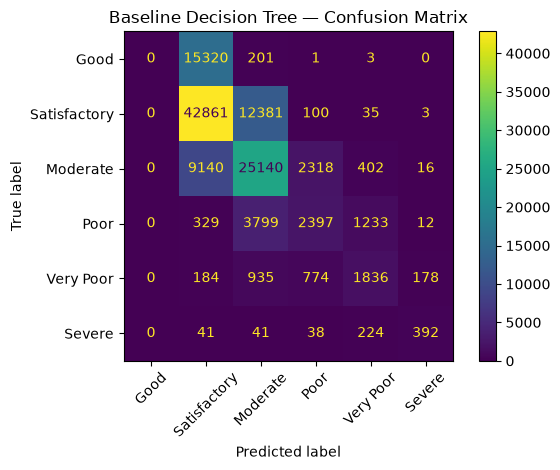

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_labels = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

cm = confusion_matrix(
    y_test_complete,
    y_pred_baseline,
    labels=class_labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

disp.plot(xticks_rotation=45)
plt.title("Baseline Decision Tree — Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train_complete, y_train_complete)

y_pred_dummy = dummy_model.predict(X_test_complete)

dummy_accuracy = accuracy_score(y_test_complete, y_pred_dummy)

dummy_macro_f1 = f1_score(
    y_test_complete,
    y_pred_dummy,
    average="macro",
    zero_division=0
)

dummy_weighted_f1 = f1_score(
    y_test_complete,
    y_pred_dummy,
    average="weighted",
    zero_division=0
)

print(f"Dummy Accuracy:     {dummy_accuracy:.4f}")
print(f"Dummy Macro F1:     {dummy_macro_f1:.4f}")
print(f"Dummy Weighted F1:  {dummy_weighted_f1:.4f}")

Dummy Accuracy:     0.3076
Dummy Macro F1:     0.0784
Dummy Weighted F1:  0.1447


In [ ]:
baseline_results = pd.DataFrame({
    "Model": ["Dummy Classifier", "Decision Tree"],
    "Accuracy": [dummy_accuracy, accuracy],
    "Macro F1": [dummy_macro_f1, macro_f1],
    "Weighted F1": [dummy_weighted_f1, weighted_f1]
})

baseline_results

,Model,Accuracy,Macro F1,Weighted F1
0,Dummy Classifier,0.307610,0.078415,0.144728
1,Decision Tree,0.603537,0.458777,0.556888


In [ ]:
print("Training data — missing values:")
print(X_train.isna().sum())

print("\nTest data — missing values:")
print(X_test.isna().sum())

Training data — missing values:
PM2.5       21134
PM10       153709
NO          13246
NO2         14183
NOx         41150
NH3        132581
CO          22393
SO2         23495
O3          21468
Benzene     64727
dtype: int64

Test data — missing values:
PM2.5       9901
PM10       25154
NO          8235
NO2         8084
NOx        10756
NH3        31413
CO          6753
SO2         9563
O3         11904
Benzene    31638
dtype: int64


In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Training shape:", X_train_imputed.shape)
print("Test shape:", X_test_imputed.shape)

print("\nMissing values remaining in training data:",
      X_train_imputed.isna().sum().sum())

print("Missing values remaining in test data:",
      X_test_imputed.isna().sum().sum())

Training shape: (372595, 10)
Test shape: (206200, 10)

Missing values remaining in training data: 0
Missing values remaining in test data: 0


In [ ]:
from sklearn.tree import DecisionTreeClassifier

imputed_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

imputed_model.fit(X_train_imputed, y_train)

print("Imputed-data Decision Tree trained successfully!")

Imputed-data Decision Tree trained successfully!


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

y_pred_imputed = imputed_model.predict(X_test_imputed)

imputed_accuracy = accuracy_score(y_test, y_pred_imputed)

imputed_macro_f1 = f1_score(
    y_test,
    y_pred_imputed,
    average="macro",
    zero_division=0
)

imputed_weighted_f1 = f1_score(
    y_test,
    y_pred_imputed,
    average="weighted",
    zero_division=0
)

print(f"Imputed Model Accuracy:    {imputed_accuracy:.4f}")
print(f"Imputed Model Macro F1:    {imputed_macro_f1:.4f}")
print(f"Imputed Model Weighted F1: {imputed_weighted_f1:.4f}")

Imputed Model Accuracy:    0.5998
Imputed Model Macro F1:    0.4721
Imputed Model Weighted F1: 0.5591


In [ ]:
# Evaluate the imputed model on the same rows used
# to evaluate the complete-case model.

X_test_imputed_common = X_test_imputed.loc[X_test_complete.index]
y_test_common = y_test.loc[X_test_complete.index]

y_pred_imputed_common = imputed_model.predict(
    X_test_imputed_common
)

print("Common test observations:", len(y_test_common))

print(
    f"Complete-case model accuracy: "
    f"{accuracy_score(y_test_complete, y_pred_baseline):.4f}"
)

print(
    f"Imputed model accuracy:       "
    f"{accuracy_score(y_test_common, y_pred_imputed_common):.4f}"
)

print(
    f"Complete-case model macro F1: "
    f"{f1_score(y_test_complete, y_pred_baseline, average='macro', zero_division=0):.4f}"
)

print(
    f"Imputed model macro F1:       "
    f"{f1_score(y_test_common, y_pred_imputed_common, average='macro', zero_division=0):.4f}"
)

Common test observations: 120334
Complete-case model accuracy: 0.6035
Imputed model accuracy:       0.6179
Complete-case model macro F1: 0.4588
Imputed model macro F1:       0.4648


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_imputed,
        labels=[
            "Good",
            "Satisfactory",
            "Moderate",
            "Poor",
            "Very Poor",
            "Severe"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

        Good       0.00      0.00      0.00     23799
Satisfactory       0.64      0.75      0.69     87237
    Moderate       0.58      0.70      0.63     65537
        Poor       0.41      0.33      0.37     15205
   Very Poor       0.53      0.50      0.51      9963
      Severe       0.67      0.59      0.63      4459

    accuracy                           0.60    206200
   macro avg       0.47      0.48      0.47    206200
weighted avg       0.53      0.60      0.56    206200



In [ ]:
print("Actual test class counts:")
print(y_test.value_counts())

print("\nImputed model predicted class counts:")
print(
    pd.Series(y_pred_imputed, name="Predicted AQI Class")
    .value_counts()
    .reindex([
        "Good",
        "Satisfactory",
        "Moderate",
        "Poor",
        "Very Poor",
        "Severe"
    ], fill_value=0)
)

Actual test class counts:
AQI_Bucket
Satisfactory    87237
Moderate        65537
Good            23799
Poor            15205
Very Poor        9963
Severe           4459
Name: count, dtype: int64

Imputed model predicted class counts:
Predicted AQI Class
Good                 0
Satisfactory    102285
Moderate         78335
Poor             12271
Very Poor         9377
Severe            3932
Name: count, dtype: int64


In [ ]:
from sklearn.tree import DecisionTreeClassifier

weighted_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

weighted_model.fit(X_train_imputed, y_train)

print("Class-weighted Decision Tree trained successfully!")

Class-weighted Decision Tree trained successfully!


In [ ]:
from sklearn.metrics import classification_report

y_pred_weighted = weighted_model.predict(X_test_imputed)

print(
    classification_report(
        y_test,
        y_pred_weighted,
        labels=[
            "Good",
            "Satisfactory",
            "Moderate",
            "Poor",
            "Very Poor",
            "Severe"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

        Good       0.33      0.91      0.49     23799
Satisfactory       0.62      0.49      0.55     87237
    Moderate       0.70      0.43      0.53     65537
        Poor       0.38      0.37      0.38     15205
   Very Poor       0.51      0.44      0.47      9963
      Severe       0.52      0.76      0.62      4459

    accuracy                           0.52    206200
   macro avg       0.51      0.57      0.51    206200
weighted avg       0.58      0.52      0.52    206200



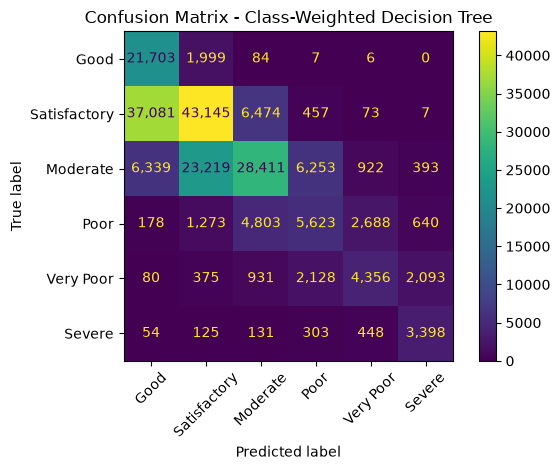

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_labels = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

cm = confusion_matrix(
    y_test,
    y_pred_weighted,
    labels=class_labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

disp.plot(
    xticks_rotation=45,
    values_format=","
)

plt.title("Confusion Matrix - Class-Weighted Decision Tree")
plt.tight_layout()
plt.show()

In [ ]:

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_weighted,
    zero_division=0
))



              precision    recall  f1-score   support

        Good       0.33      0.91      0.49     23799
    Moderate       0.70      0.43      0.53     65537
        Poor       0.38      0.37      0.38     15205
Satisfactory       0.62      0.49      0.55     87237
      Severe       0.52      0.76      0.62      4459
   Very Poor       0.51      0.44      0.47      9963

    accuracy                           0.52    206200
   macro avg       0.51      0.57      0.51    206200
weighted avg       0.58      0.52      0.52    206200



In [ ]:
%whos

Variable                  Type                      Data/Info
-------------------------------------------------------------
ConfusionMatrixDisplay    type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DecisionTreeClassifier    ABCMeta                   <class 'sklearn.tree._cla<...>.DecisionTreeClassifier'>
DummyClassifier           type                      <class 'sklearn.dummy.DummyClassifier'>
SimpleImputer             type                      <class 'sklearn.impute._base.SimpleImputer'>
X                         DataFrame                 Shape: (578795, 10)
X_test                    DataFrame                 Shape: (206200, 10)
X_test_complete           DataFrame                 Shape: (120334, 10)
X_test_imputed            DataFrame                 Shape: (206200, 10)
X_test_imputed_common     DataFrame                 Shape: (120334, 10)
X_train                   DataFrame                 Shape: (372595, 10)
X_train_complete          DataFrame    

In [ ]:
%whos

Variable                  Type                      Data/Info
-------------------------------------------------------------
ConfusionMatrixDisplay    type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DecisionTreeClassifier    ABCMeta                   <class 'sklearn.tree._cla<...>.DecisionTreeClassifier'>
DummyClassifier           type                      <class 'sklearn.dummy.DummyClassifier'>
SimpleImputer             type                      <class 'sklearn.impute._base.SimpleImputer'>
X                         DataFrame                 Shape: (578795, 10)
X_test                    DataFrame                 Shape: (206200, 10)
X_test_complete           DataFrame                 Shape: (120334, 10)
X_test_imputed            DataFrame                 Shape: (206200, 10)
X_test_imputed_common     DataFrame                 Shape: (120334, 10)
X_train                   DataFrame                 Shape: (372595, 10)
X_train_complete          DataFrame    

In [ ]:
# Inspect the baseline model
print("Baseline model:")
print(baseline_model)

# Check whether it uses class weighting
print("\nClass weights:")
print(baseline_model.class_weight)

Baseline model:
DecisionTreeClassifier(max_depth=5, random_state=42)

Class weights:
None


In [ ]:
for name, obj in list(globals().items()):
    if isinstance(obj, DecisionTreeClassifier):
        print(
            f"Variable: {name} | "
            f"Class weight: {obj.class_weight} | "
            f"Max depth: {obj.max_depth}"
        )

Variable: baseline_model | Class weight: None | Max depth: 5
Variable: imputed_model | Class weight: None | Max depth: 5
Variable: weighted_model | Class weight: balanced | Max depth: 5


In [ ]:
print("Baseline training data:", X_train_complete.shape)
print("Common test data:", X_test_complete.shape)
print("Common test labels:", y_test_common.shape)

print("\nBaseline model:", baseline_model)
print("Weighted model:", weighted_model)

Baseline training data: (144992, 10)
Common test data: (120334, 10)
Common test labels: (120334,)

Baseline model: DecisionTreeClassifier(max_depth=5, random_state=42)
Weighted model: DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42)


In [ ]:
# Generate predictions on the same test observations
y_pred_baseline = baseline_model.predict(X_test_complete)
y_pred_weighted = weighted_model.predict(X_test_complete)

print("Baseline predictions:", len(y_pred_baseline))
print("Weighted predictions:", len(y_pred_weighted))
print("Actual test labels:", len(y_test_common))

Baseline predictions: 120334
Weighted predictions: 120334
Actual test labels: 120334


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Calculate metrics for both models
baseline_accuracy = accuracy_score(y_test_common, y_pred_baseline)
baseline_macro_f1 = f1_score(y_test_common, y_pred_baseline, average="macro")
baseline_weighted_f1 = f1_score(y_test_common, y_pred_baseline, average="weighted")

weighted_accuracy = accuracy_score(y_test_common, y_pred_weighted)
weighted_macro_f1 = f1_score(y_test_common, y_pred_weighted, average="macro")
weighted_weighted_f1 = f1_score(y_test_common, y_pred_weighted, average="weighted")

# Display side-by-side comparison
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1", "Weighted F1"],
    "Baseline Model": [
        baseline_accuracy,
        baseline_macro_f1,
        baseline_weighted_f1
    ],
    "Class-Weighted Model": [
        weighted_accuracy,
        weighted_macro_f1,
        weighted_weighted_f1
    ]
})

print(comparison.to_string(index=False))

     Metric  Baseline Model  Class-Weighted Model
   Accuracy        0.603537              0.510670
   Macro F1        0.458777              0.484653
Weighted F1        0.556888              0.517590


In [ ]:
from sklearn.metrics import classification_report

print("BASELINE MODEL")
print(classification_report(
    y_test_common,
    y_pred_baseline,
    zero_division=0
))

print("\nCLASS-WEIGHTED MODEL")
print(classification_report(
    y_test_common,
    y_pred_weighted,
    zero_division=0
))

BASELINE MODEL
              precision    recall  f1-score   support

        Good       0.00      0.00      0.00     15525
    Moderate       0.59      0.68      0.63     37016
        Poor       0.43      0.31      0.36      7770
Satisfactory       0.63      0.77      0.70     55380
      Severe       0.65      0.53      0.59       736
   Very Poor       0.49      0.47      0.48      3907

    accuracy                           0.60    120334
   macro avg       0.47      0.46      0.46    120334
weighted avg       0.52      0.60      0.56    120334


CLASS-WEIGHTED MODEL
              precision    recall  f1-score   support

        Good       0.32      0.95      0.48     15525
    Moderate       0.70      0.48      0.57     37016
        Poor       0.39      0.39      0.39      7770
Satisfactory       0.65      0.43      0.52     55380
      Severe       0.44      0.59      0.51       736
   Very Poor       0.44      0.45      0.44      3907

    accuracy                           0

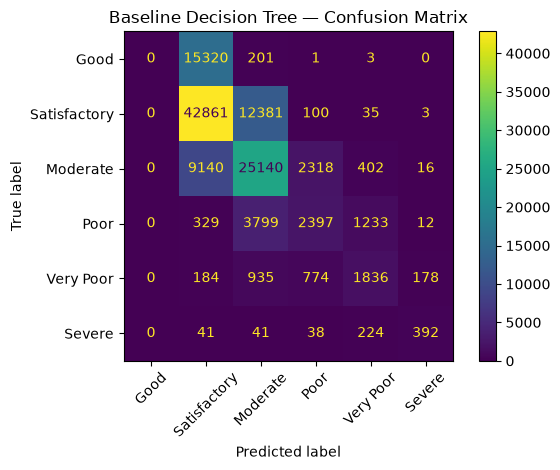

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

cm_baseline = confusion_matrix(
    y_test_common,
    y_pred_baseline,
    labels=class_order
)

display_baseline = ConfusionMatrixDisplay(
    confusion_matrix=cm_baseline,
    display_labels=class_order
)

display_baseline.plot(
    xticks_rotation=45,
    values_format="d"
)

plt.title("Baseline Decision Tree — Confusion Matrix")
plt.tight_layout()
plt.show()

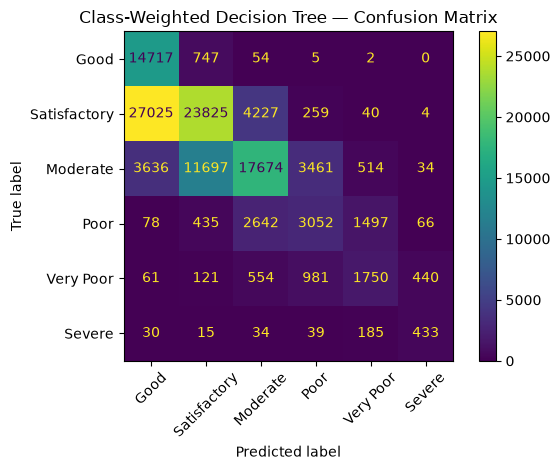

In [ ]:
cm_weighted = confusion_matrix(
    y_test_common,
    y_pred_weighted,
    labels=class_order
)

display_weighted = ConfusionMatrixDisplay(
    confusion_matrix=cm_weighted,
    display_labels=class_order
)

display_weighted.plot(
    xticks_rotation=45,
    values_format="d"
)

plt.title("Class-Weighted Decision Tree — Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
print("Complete-case training rows:", len(X_train_complete))
print("Imputed training rows:", len(X_train_imputed))

print("\nBaseline model class weights:", baseline_model.class_weight)
print("Weighted model class weights:", weighted_model.class_weight)

Complete-case training rows: 144992
Imputed training rows: 372595

Baseline model class weights: None
Weighted model class weights: balanced


In [ ]:
print("Baseline model training setup:")
print("Training rows:", len(X_train_complete))
print("Features:", list(X_train_complete.columns))

print("\nWeighted model training setup:")
print("Training rows with imputation:", len(X_train_imputed))
print("Features:", list(X_train_imputed.columns))

Baseline model training setup:
Training rows: 144992
Features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene']

Weighted model training setup:
Training rows with imputation: 372595
Features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene']


In [ ]:
weighted_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)
weighted_model.fit(X_train_imputed, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_feat

In [ ]:
# Train a class-weighted Decision Tree on the same complete cases
weighted_complete_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

weighted_complete_model.fit(X_train_complete, y_train_complete)

print("Training observations:", len(X_train_complete))
print("Training labels:", len(y_train_complete))
print("Class weighting:", weighted_complete_model.class_weight)


Training observations: 144992
Training labels: 144992
Class weighting: balanced


In [ ]:
# Predict on the same complete test observations
y_pred_weighted_complete = weighted_complete_model.predict(X_test_complete)

print("Actual test observations:", len(y_test_common))
print("Baseline predictions:", len(y_pred_baseline))
print("Weighted predictions:", len(y_pred_weighted_complete))

Actual test observations: 120334
Baseline predictions: 120334
Weighted predictions: 120334


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

# Baseline metrics
baseline_accuracy = accuracy_score(y_test_common, y_pred_baseline)
baseline_macro_f1 = f1_score(
    y_test_common, y_pred_baseline, average="macro", zero_division=0
)
baseline_weighted_f1 = f1_score(
    y_test_common, y_pred_baseline, average="weighted", zero_division=0
)

# Class-weighted model trained on the same complete cases
weighted_accuracy = accuracy_score(y_test_common, y_pred_weighted_complete)
weighted_macro_f1 = f1_score(
    y_test_common, y_pred_weighted_complete, average="macro", zero_division=0
)
weighted_f1 = f1_score(
    y_test_common, y_pred_weighted_complete, average="weighted", zero_division=0
)

# Display comparison
comparison_fair = pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1", "Weighted F1"],
    "Baseline": [
        baseline_accuracy,
        baseline_macro_f1,
        baseline_weighted_f1
    ],
    "Class-Weighted": [
        weighted_accuracy,
        weighted_macro_f1,
        weighted_f1
    ]
})

print(comparison_fair.round(4).to_string(index=False))

     Metric  Baseline  Class-Weighted
   Accuracy    0.6035          0.5441
   Macro F1    0.4588          0.4862
Weighted F1    0.5569          0.5522


In [ ]:
from sklearn.metrics import classification_report

class_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

print("BASELINE MODEL")
print(classification_report(
    y_test_common,
    y_pred_baseline,
    labels=class_order,
    zero_division=0
))

print("\nCLASS-WEIGHTED MODEL — COMPLETE CASES")
print(classification_report(
    y_test_common,
    y_pred_weighted_complete,
    labels=class_order,
    zero_division=0
))

BASELINE MODEL
              precision    recall  f1-score   support

        Good       0.00      0.00      0.00     15525
Satisfactory       0.63      0.77      0.70     55380
    Moderate       0.59      0.68      0.63     37016
        Poor       0.43      0.31      0.36      7770
   Very Poor       0.49      0.47      0.48      3907
      Severe       0.65      0.53      0.59       736

    accuracy                           0.60    120334
   macro avg       0.47      0.46      0.46    120334
weighted avg       0.52      0.60      0.56    120334


CLASS-WEIGHTED MODEL — COMPLETE CASES
              precision    recall  f1-score   support

        Good       0.42      0.84      0.56     15525
Satisfactory       0.71      0.59      0.64     55380
    Moderate       0.71      0.36      0.47     37016
        Poor       0.23      0.55      0.32      7770
   Very Poor       0.40      0.45      0.42      3907
      Severe       0.39      0.66      0.49       736

    accuracy           

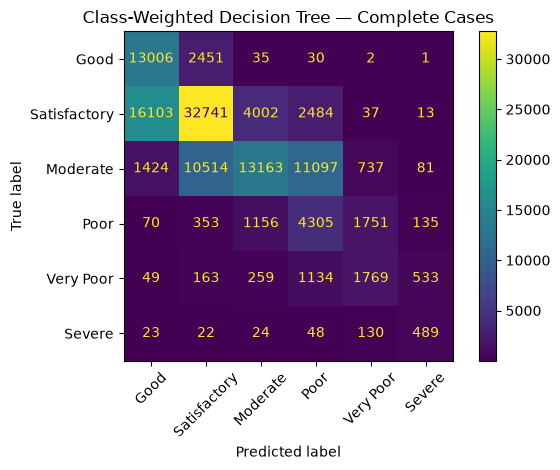

In [ ]:
cm_weighted_complete = confusion_matrix(
    y_test_common,
    y_pred_weighted_complete,
    labels=class_order
)

display_weighted_complete = ConfusionMatrixDisplay(
    confusion_matrix=cm_weighted_complete,
    display_labels=class_order
)

display_weighted_complete.plot(
    xticks_rotation=45,
    values_format="d"
)

plt.title("Class-Weighted Decision Tree — Complete Cases")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

models = {
    "Baseline": y_pred_baseline,
    "Weighted (Imputed)": y_pred_weighted,
    "Weighted (Complete)": y_pred_weighted_complete
}

class_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

results = []

for model_name, predictions in models.items():
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test_common,
        predictions,
        labels=class_order,
        zero_division=0
    )

    for i, class_name in enumerate(class_order):
        results.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": precision[i],
            "Recall": recall[i],
            "F1": f1[i],
            "Support": support[i]
        })

class_comparison = pd.DataFrame(results)

print(class_comparison.round(3).to_string(index=False))

              Model        Class  Precision  Recall    F1  Support
           Baseline         Good      0.000   0.000 0.000    15525
           Baseline Satisfactory      0.631   0.774 0.695    55380
           Baseline     Moderate      0.592   0.679 0.632    37016
           Baseline         Poor      0.426   0.308 0.358     7770
           Baseline    Very Poor      0.492   0.470 0.481     3907
           Baseline       Severe      0.652   0.533 0.586      736
 Weighted (Imputed)         Good      0.323   0.948 0.482    15525
 Weighted (Imputed) Satisfactory      0.647   0.430 0.517    55380
 Weighted (Imputed)     Moderate      0.702   0.477 0.568    37016
 Weighted (Imputed)         Poor      0.391   0.393 0.392     7770
 Weighted (Imputed)    Very Poor      0.439   0.448 0.443     3907
 Weighted (Imputed)       Severe      0.443   0.588 0.506      736
Weighted (Complete)         Good      0.424   0.838 0.563    15525
Weighted (Complete) Satisfactory      0.708   0.591 0.644    5

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

# Give each class a weight.
# A weight of 1.0 means no adjustment.
# Higher values give that class more influence during training.

custom_weights = {
    "Gentle": {
        "Good": 1.5,
        "Satisfactory": 1.0,
        "Moderate": 1.0,
        "Poor": 1.5,
        "Very Poor": 1.5,
        "Severe": 1.5,
    },
    "Moderate": {
        "Good": 2.0,
        "Satisfactory": 1.0,
        "Moderate": 1.0,
        "Poor": 2.0,
        "Very Poor": 2.0,
        "Severe": 2.0,
    },
}

weight_results = []

for setting_name, weights in custom_weights.items():
    model = DecisionTreeClassifier(
        max_depth=5,
        class_weight=weights,
        random_state=42,
    )

    model.fit(X_train_complete, y_train_complete)
    predictions = model.predict(X_test_complete)

    weight_results.append({
        "Setting": setting_name,
        "Accuracy": accuracy_score(y_test_common, predictions),
        "Macro F1": f1_score(
            y_test_common,
            predictions,
            average="macro",
            zero_division=0,
        ),
        "Weighted F1": f1_score(
            y_test_common,
            predictions,
            average="weighted",
            zero_division=0,
        ),
    })

weight_results_df = pd.DataFrame(weight_results)

print(weight_results_df.round(4).to_string(index=False))

 Setting  Accuracy  Macro F1  Weighted F1
  Gentle    0.6165    0.4641       0.5680
Moderate    0.6006    0.5552       0.6045


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

class_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe",
]

custom_weights = {
    "Gentle": {
        "Good": 1.5,
        "Satisfactory": 1.0,
        "Moderate": 1.0,
        "Poor": 1.5,
        "Very Poor": 1.5,
        "Severe": 1.5,
    },
    "Moderate": {
        "Good": 2.0,
        "Satisfactory": 1.0,
        "Moderate": 1.0,
        "Poor": 2.0,
        "Very Poor": 2.0,
        "Severe": 2.0,
    },
}

custom_models = {}
custom_predictions = {}

for setting_name, weights in custom_weights.items():
    current_model = DecisionTreeClassifier(
        max_depth=5,
        class_weight=weights,
        random_state=42,
    )

    current_model.fit(X_train_complete, y_train_complete)

    custom_models[setting_name] = current_model
    custom_predictions[setting_name] = (
        current_model.predict(X_test_complete)
    )

    print(f"\n{'=' * 20} {setting_name.upper()} {'=' * 20}")

    print(
        classification_report(
            y_test_common,
            custom_predictions[setting_name],
            labels=class_order,
            zero_division=0,
        )
    )


==================== GENTLE ====================
              precision    recall  f1-score   support

        Good       0.00      0.00      0.00     15525
Satisfactory       0.64      0.80      0.71     55380
    Moderate       0.62      0.68      0.65     37016
        Poor       0.44      0.31      0.36      7770
   Very Poor       0.49      0.46      0.48      3907
      Severe       0.65      0.53      0.59       736

    accuracy                           0.62    120334
   macro avg       0.47      0.46      0.46    120334
weighted avg       0.53      0.62      0.57    120334


==================== MODERATE ====================
              precision    recall  f1-score   support

        Good       0.50      0.70      0.58     15525
Satisfactory       0.73      0.57      0.64     55380
    Moderate       0.59      0.64      0.61     37016
        Poor       0.37      0.49      0.43      7770
   Very Poor       0.50      0.47      0.48      3907
      Severe       0.68      0

In [ ]:
from sklearn.metrics import confusion_matrix
import pandas as pd

class_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe",
]

# Predictions from the baseline and moderate custom-weighted models
baseline_predictions = y_pred_baseline
moderate_predictions = custom_predictions["Moderate"]

baseline_cm = confusion_matrix(
    y_test_common,
    baseline_predictions,
    labels=class_order,
)

moderate_cm = confusion_matrix(
    y_test_common,
    moderate_predictions,
    labels=class_order,
)

print("BASELINE CONFUSION MATRIX")
print(pd.DataFrame(
    baseline_cm,
    index=[f"Actual {c}" for c in class_order],
    columns=[f"Predicted {c}" for c in class_order],
))

print("\nMODERATE CUSTOM-WEIGHTED CONFUSION MATRIX")
print(pd.DataFrame(
    moderate_cm,
    index=[f"Actual {c}" for c in class_order],
    columns=[f"Predicted {c}" for c in class_order],
))

BASELINE CONFUSION MATRIX
                     Predicted Good  Predicted Satisfactory  \
Actual Good                       0                   15320   
Actual Satisfactory               0                   42861   
Actual Moderate                   0                    9140   
Actual Poor                       0                     329   
Actual Very Poor                  0                     184   
Actual Severe                     0                      41   

                     Predicted Moderate  Predicted Poor  Predicted Very Poor  \
Actual Good                         201               1                    3   
Actual Satisfactory               12381             100                   35   
Actual Moderate                   25140            2318                  402   
Actual Poor                        3799            2397                 1233   
Actual Very Poor                    935             774                 1836   
Actual Severe                        41             

In [ ]:
moderate_cm_df = pd.DataFrame(
    moderate_cm,
    index=[f"Actual {c}" for c in class_order],
    columns=[f"Predicted {c}" for c in class_order],
)

print(moderate_cm_df.to_string())

                     Predicted Good  Predicted Satisfactory  Predicted Moderate  Predicted Poor  Predicted Very Poor  Predicted Severe
Actual Good                   10920                    4217                 379               7                    2                 0
Actual Satisfactory           10098                   31785               13105             354                   35                 3
Actual Moderate                 828                    7577               23511            4692                  393                15
Actual Poor                      26                     157                2537            3833                 1206                11
Actual Very Poor                 29                      71                 524            1294                 1838               151
Actual Severe                    18                      25                  33              44                  234               382


In [ ]:
print("Training period:")
print("Start:", model_df.loc[train_mask, "Datetime"].min())
print("End:  ", model_df.loc[train_mask, "Datetime"].max())

print("\nTest period:")
print("Start:", model_df.loc[test_mask, "Datetime"].min())
print("End:  ", model_df.loc[test_mask, "Datetime"].max())

print("\nTraining observations:", len(X_train))
print("Test observations:", len(X_test))

Training period:
Start: 2015-01-01 16:00:00


End:   2019-05-26 12:00:00

Test period:
Start: 2019-05-26 13:00:00
End:   2020-07-01 00:00:00

Training observations: 372595
Test observations: 206200


In [ ]:
# Check the datasets and labels currently available

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)

print("\nTraining labels:", y_train.shape)
print("Test labels:", y_test.shape)

print("\nExisting complete-case training data:", X_train_complete.shape)
print("Existing complete-case test data:", X_test_complete.shape)

Training data: (372595, 10)
Test data: (206200, 10)

Training labels: (372595,)
Test labels: (206200,)

Existing complete-case training data: (144992, 10)
Existing complete-case test data: (120334, 10)


In [ ]:

# Create a validation split from the existing training period

train_times = np.sort(
    model_df.loc[train_mask, "Datetime"].unique()
)

validation_cutoff_index = int(len(train_times) * 0.8)
validation_cutoff_time = train_times[validation_cutoff_index]

fit_mask = train_mask & (model_df["Datetime"] < validation_cutoff_time)
validation_mask = train_mask & (model_df["Datetime"] >= validation_cutoff_time)

X_fit = X.loc[fit_mask]
y_fit = y.loc[fit_mask]

X_val = X.loc[validation_mask]
y_val = y.loc[validation_mask]

print("Model-fitting period:")
print("Start:", model_df.loc[fit_mask, "Datetime"].min())
print("End:  ", model_df.loc[fit_mask, "Datetime"].max())

print("\nValidation period:")
print("Start:", model_df.loc[validation_mask, "Datetime"].min())
print("End:  ", model_df.loc[validation_mask, "Datetime"].max())

print("\nModel-fitting observations:", len(X_fit))
print("Validation observations:", len(X_val))
print("Existing test observations:", len(X_test))



Model-fitting period:
Start: 2015-01-01 16:00:00
End:   2018-07-09 07:00:00

Validation period:
Start: 2018-07-09 08:00:00
End:   2019-05-26 12:00:00

Model-fitting observations: 242225
Validation observations: 130370
Existing test observations: 206200


In [ ]:

# Keep observations with no missing pollutant features
# in the model-fitting and validation periods.

fit_complete_mask = X_fit.notna().all(axis=1)
val_complete_mask = X_val.notna().all(axis=1)

X_fit_complete = X_fit.loc[fit_complete_mask]
y_fit_complete = y_fit.loc[fit_complete_mask]

X_val_complete = X_val.loc[val_complete_mask]
y_val_complete = y_val.loc[val_complete_mask]

print("Complete-case model-fitting observations:", len(X_fit_complete))
print("Complete-case validation observations:", len(X_val_complete))

print("\nMissing values in model-fitting data:",
      X_fit_complete.isna().sum().sum())

print("Missing values in validation data:",
      X_val_complete.isna().sum().sum())

print("\nTraining class distribution:")
print(y_fit_complete.value_counts().sort_index())

print("\nValidation class distribution:")
print(y_val_complete.value_counts().sort_index())



Complete-case model-fitting observations: 86161
Complete-case validation observations: 58831

Missing values in model-fitting data: 0
Missing values in validation data: 0

Training class distribution:
AQI_Bucket
Good             2412
Moderate        35254
Poor            13933
Satisfactory    18765
Severe           4481
Very Poor       11316
Name: count, dtype: int64

Validation class distribution:
AQI_Bucket
Good             2461
Moderate        25571
Poor             6787
Satisfactory    18166
Severe           1349
Very Poor        4497
Name: count, dtype: int64


In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Train the baseline model
validation_baseline = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

validation_baseline.fit(
    X_fit_complete,
    y_fit_complete
)

# Predict on the validation set
y_val_pred = validation_baseline.predict(X_val_complete)

# Evaluate performance
print("Validation Accuracy:",
      round(accuracy_score(y_val_complete, y_val_pred), 4))

print("Validation Macro F1:",
      round(f1_score(
          y_val_complete,
          y_val_pred,
          average="macro",
          zero_division=0
      ), 4))

print("Validation Weighted F1:",
      round(f1_score(
          y_val_complete,
          y_val_pred,
          average="weighted",
          zero_division=0
      ), 4))

print("\nClassification Report:")
print(classification_report(
    y_val_complete,
    y_val_pred,
    zero_division=0
))



Validation Accuracy: 0.6279
Validation Macro F1: 0.464
Validation Weighted F1: 0.6052

Classification Report:
              precision    recall  f1-score   support

        Good       0.00      0.00      0.00      2461
    Moderate       0.65      0.82      0.72     25571
        Poor       0.46      0.36      0.40      6787
Satisfactory       0.66      0.60      0.63     18166
      Severe       0.60      0.47      0.53      1349
   Very Poor       0.56      0.45      0.50      4497

    accuracy                           0.63     58831
   macro avg       0.49      0.45      0.46     58831
weighted avg       0.60      0.63      0.61     58831



In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Train a class-weighted Decision Tree
balanced_validation_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

balanced_validation_model.fit(
    X_fit_complete,
    y_fit_complete
)

# Predict on the same validation observations
y_val_balanced_pred = balanced_validation_model.predict(
    X_val_complete
)

# Evaluate performance
print("Validation Accuracy:",
      round(accuracy_score(
          y_val_complete,
          y_val_balanced_pred
      ), 4))

print("Validation Macro F1:",
      round(f1_score(
          y_val_complete,
          y_val_balanced_pred,
          average="macro",
          zero_division=0
      ), 4))

print("Validation Weighted F1:",
      round(f1_score(
          y_val_complete,
          y_val_balanced_pred,
          average="weighted",
          zero_division=0
      ), 4))

print("\nClassification Report:")
print(classification_report(
    y_val_complete,
    y_val_balanced_pred,
    zero_division=0
))



Validation Accuracy: 0.5607
Validation Macro F1: 0.4905
Validation Weighted F1: 0.5652

Classification Report:
              precision    recall  f1-score   support

        Good       0.33      0.78      0.46      2461
    Moderate       0.66      0.65      0.66     25571
        Poor       0.29      0.28      0.29      6787
Satisfactory       0.68      0.52      0.59     18166
      Severe       0.43      0.58      0.49      1349
   Very Poor       0.42      0.50      0.46      4497

    accuracy                           0.56     58831
   macro avg       0.47      0.55      0.49     58831
weighted avg       0.58      0.56      0.57     58831



In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Give selected classes greater importance during training
custom_weights = {
    "Good": 2.0,
    "Satisfactory": 1.0,
    "Moderate": 1.0,
    "Poor": 2.0,
    "Very Poor": 2.0,
    "Severe": 2.0
}

custom_validation_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight=custom_weights,
    random_state=42
)

custom_validation_model.fit(
    X_fit_complete,
    y_fit_complete
)

# Evaluate on the same validation observations
y_val_custom_pred = custom_validation_model.predict(
    X_val_complete
)

print("Validation Accuracy:",
      round(accuracy_score(
          y_val_complete,
          y_val_custom_pred
      ), 4))

print("Validation Macro F1:",
      round(f1_score(
          y_val_complete,
          y_val_custom_pred,
          average="macro",
          zero_division=0
      ), 4))

print("Validation Weighted F1:",
      round(f1_score(
          y_val_complete,
          y_val_custom_pred,
          average="weighted",
          zero_division=0
      ), 4))

print("\nClassification Report:")
print(classification_report(
    y_val_complete,
    y_val_custom_pred,
    zero_division=0
))



Validation Accuracy: 0.6184
Validation Macro F1: 0.4624
Validation Weighted F1: 0.6003

Classification Report:
              precision    recall  f1-score   support

        Good       0.00      0.00      0.00      2461
    Moderate       0.66      0.79      0.72     25571
        Poor       0.44      0.37      0.40      6787
Satisfactory       0.67      0.58      0.62     18166
      Severe       0.60      0.49      0.54      1349
   Very Poor       0.45      0.54      0.49      4497

    accuracy                           0.62     58831
   macro avg       0.47      0.46      0.46     58831
weighted avg       0.59      0.62      0.60     58831



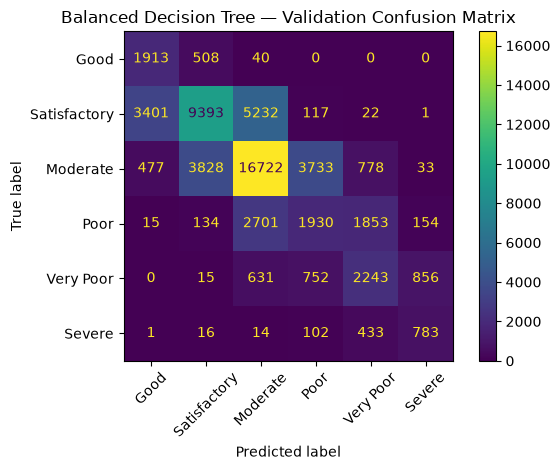

In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Use the same class order throughout our analysis
class_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

# Calculate the confusion matrix
cm_balanced = confusion_matrix(
    y_val_complete,
    y_val_balanced_pred,
    labels=class_order
)

# Display the matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=class_order
)

disp.plot(values_format="d", xticks_rotation=45)
plt.title("Balanced Decision Tree — Validation Confusion Matrix")
plt.tight_layout()
plt.show()



In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

models = {
    "Baseline": y_val_pred,
    "Balanced": y_val_balanced_pred,
    "Custom Weights": y_val_custom_pred
}

class_names = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

comparison = []

for model_name, predictions in models.items():
    report = classification_report(
        y_val_complete,
        predictions,
        labels=class_names,
        output_dict=True,
        zero_division=0
    )

    for class_name in class_names:
        comparison.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1-score": report[class_name]["f1-score"]
        })

comparison_df = pd.DataFrame(comparison)

comparison_df.round(3)

,Model,Class,Precision,Recall,F1-score
0,Baseline,Good,0.000,0.000,0.000
1,Baseline,Satisfactory,0.662,0.599,0.629
2,Baseline,Moderate,0.646,0.820,0.723
3,Baseline,Poor,0.464,0.358,0.404
4,Baseline,Very Poor,0.558,0.453,0.500
5,Baseline,Severe,0.602,0.471,0.529
6,Balanced,Good,0.329,0.777,0.463
7,Balanced,Satisfactory,0.676,0.517,0.586
8,Balanced,Moderate,0.660,0.654,0.657
9,Balanced,Poor,0.291,0.284,0.288


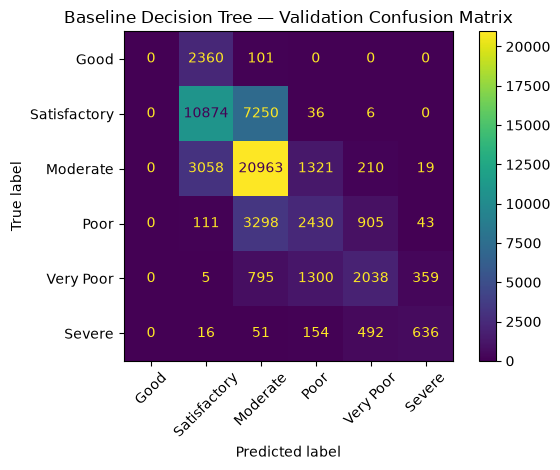

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

class_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

cm_baseline = confusion_matrix(
    y_val_complete,
    y_val_pred,
    labels=class_order
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_baseline,
    display_labels=class_order
)

disp.plot(values_format="d", xticks_rotation=45)
plt.title("Baseline Decision Tree — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
class_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

pollutant_medians = (
    X_fit_complete
    .assign(AQI_Bucket=y_fit_complete)
    .groupby("AQI_Bucket")[pollutant_features]
    .median()
    .reindex(class_order)
)

pollutant_medians.round(2)

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene
AQI_Bucket,,,,,,,,,,
Good,14.18,38.16,3.44,19.24,5.64,8.70,0.30,4.73,20.40,0.35
Satisfactory,28.03,71.30,5.23,24.92,13.88,14.61,0.57,5.53,25.43,0.75
Moderate,56.00,114.40,7.20,30.92,23.28,17.80,0.80,8.97,40.39,1.19
Poor,82.42,176.00,13.45,39.12,41.62,29.60,1.04,11.00,48.95,2.04
Very Poor,145.16,277.64,26.01,51.88,54.21,41.38,1.56,16.38,45.47,3.19
Severe,234.00,410.92,48.60,76.89,68.77,51.78,1.48,20.68,62.63,4.61


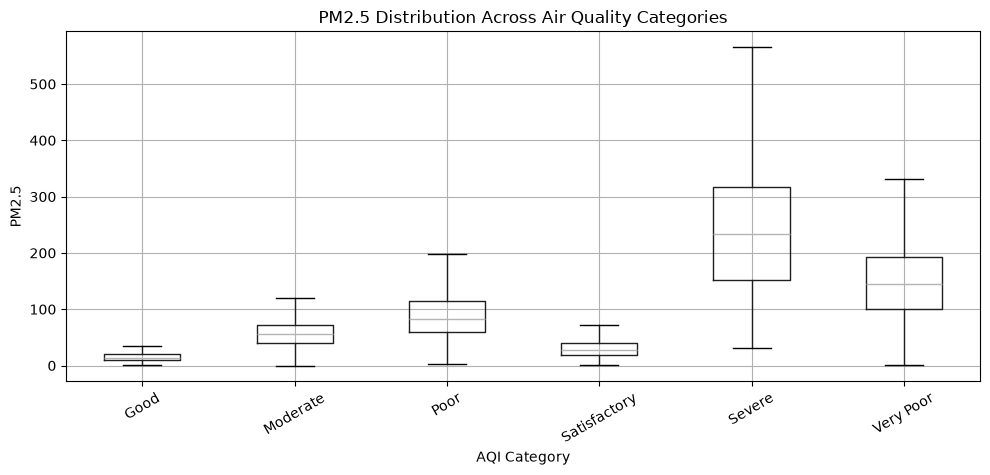

In [ ]:
import matplotlib.pyplot as plt

class_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

pm25_plot_data = X_fit_complete[["PM2.5"]].copy()
pm25_plot_data["AQI_Bucket"] = y_fit_complete

pm25_plot_data.boxplot(
    column="PM2.5",
    by="AQI_Bucket",
    figsize=(10, 5),
    showfliers=False
)

plt.title("PM2.5 Distribution Across Air Quality Categories")
plt.suptitle("")
plt.xlabel("AQI Category")
plt.ylabel("PM2.5")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

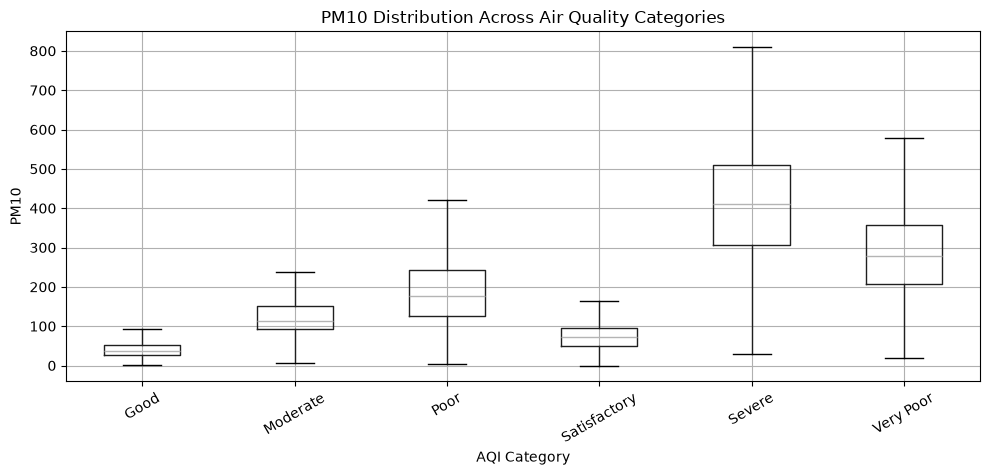

In [ ]:

pm10_plot_data = X_fit_complete[["PM10"]].copy()
pm10_plot_data["AQI_Bucket"] = y_fit_complete

pm10_plot_data.boxplot(
    column="PM10",
    by="AQI_Bucket",
    figsize=(10, 5),
    showfliers=False
)

plt.title("PM10 Distribution Across Air Quality Categories")
plt.suptitle("")
plt.xlabel("AQI Category")
plt.ylabel("PM10")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



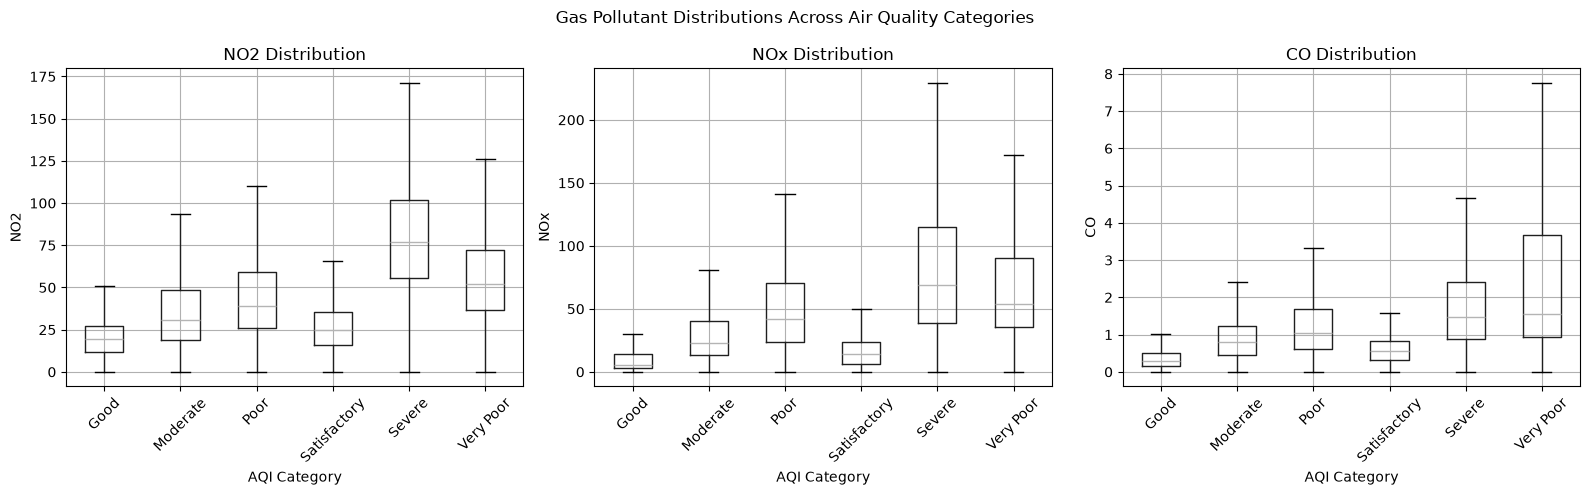

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

pollutants_to_plot = ["NO2", "NOx", "CO"]

for ax, pollutant in zip(axes, pollutants_to_plot):
    plot_data = X_fit_complete[[pollutant]].copy()
    plot_data["AQI_Bucket"] = y_fit_complete

    plot_data.boxplot(
        column=pollutant,
        by="AQI_Bucket",
        ax=ax,
        showfliers=False
    )

    ax.set_title(f"{pollutant} Distribution")
    ax.set_xlabel("AQI Category")
    ax.set_ylabel(pollutant)
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Gas Pollutant Distributions Across Air Quality Categories")
plt.tight_layout()
plt.show()



In [ ]:

# Identify observations that actually belong to the Poor class
actual_poor_mask = y_val_complete == "Poor"

# Separate correct and incorrect predictions
poor_correct_mask = (
    actual_poor_mask
    & (y_val_balanced_pred == "Poor")
)

poor_misclassified_mask = (
    actual_poor_mask
    & (y_val_balanced_pred != "Poor")
)

print("Actual Poor observations:", actual_poor_mask.sum())
print("Correctly classified as Poor:", poor_correct_mask.sum())
print("Misclassified Poor observations:", poor_misclassified_mask.sum())

print("\nPredicted categories for actual Poor observations:")
print(
    pd.Series(y_val_balanced_pred[actual_poor_mask])
    .value_counts()
)


Actual Poor observations: 6787
Correctly classified as Poor: 1930
Misclassified Poor observations: 4857

Predicted categories for actual Poor observations:
Moderate        2701
Poor            1930
Very Poor       1853
Severe           154
Satisfactory     134
Good              15
Name: count, dtype: int64


In [ ]:
# Identify actual Poor observations that the model predicts correctly
poor_correct_mask = (
    (y_val_complete == "Poor")
    & (y_val_balanced_pred == "Poor")
)

# Identify actual Poor observations predicted as Moderate
poor_as_moderate_mask = (
    (y_val_complete == "Poor")
    & (y_val_balanced_pred == "Moderate")
)

# Identify actual Poor observations predicted as Very Poor
poor_as_very_poor_mask = (
    (y_val_complete == "Poor")
    & (y_val_balanced_pred == "Very Poor")
)

# Compare the pollutant medians across these three groups
poor_error_comparison = pd.DataFrame({
    "Correctly predicted Poor": X_val_complete.loc[
        poor_correct_mask, pollutant_features
    ].median(),

    "Misclassified as Moderate": X_val_complete.loc[
        poor_as_moderate_mask, pollutant_features
    ].median(),

    "Misclassified as Very Poor": X_val_complete.loc[
        poor_as_very_poor_mask, pollutant_features
    ].median()
})

poor_error_comparison.round(2)

,Correctly predicted Poor,Misclassified as Moderate,Misclassified as Very Poor
PM2.5,100.66,72.19,143.57
PM10,195.18,128.61,290.00
NO,16.77,9.59,41.37
NO2,44.31,31.39,50.84
NOx,47.72,32.95,74.54
NH3,30.89,25.50,37.03
CO,1.10,0.98,1.79
SO2,13.98,13.36,17.56
O3,24.00,27.67,18.64
Benzene,2.79,1.58,5.15


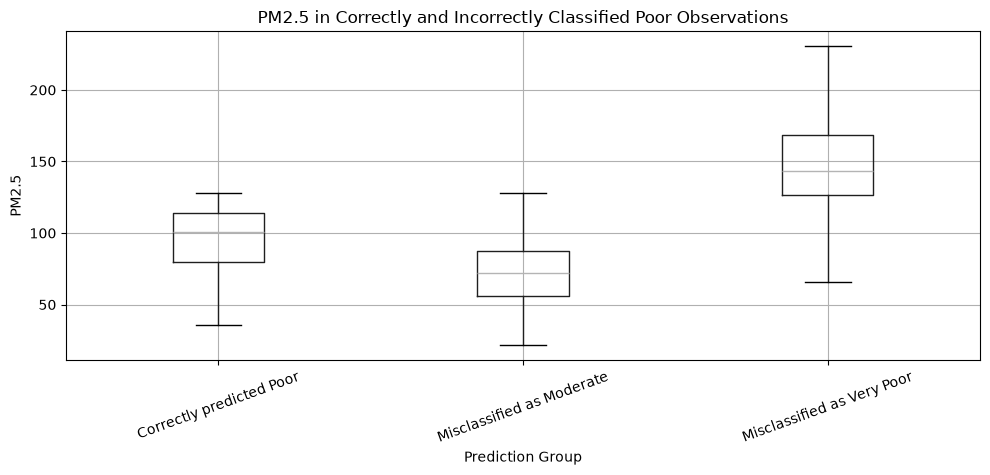

In [ ]:
import matplotlib.pyplot as plt

poor_pm25_comparison = pd.DataFrame({
    "PM2.5": X_val_complete["PM2.5"],
    "Actual": y_val_complete,
    "Predicted": y_val_balanced_pred
})

poor_pm25_comparison = poor_pm25_comparison[
    poor_pm25_comparison["Actual"] == "Poor"
].copy()

poor_pm25_comparison["Prediction Group"] = (
    poor_pm25_comparison["Predicted"].map({
        "Poor": "Correctly predicted Poor",
        "Moderate": "Misclassified as Moderate",
        "Very Poor": "Misclassified as Very Poor"
    })
)

poor_pm25_comparison = poor_pm25_comparison[
    poor_pm25_comparison["Prediction Group"].notna()
]

poor_pm25_comparison.boxplot(
    column="PM2.5",
    by="Prediction Group",
    figsize=(10, 5),
    showfliers=False
)

plt.title("PM2.5 in Correctly and Incorrectly Classified Poor Observations")
plt.suptitle("")
plt.xlabel("Prediction Group")
plt.ylabel("PM2.5")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
models_to_compare = {
    "Baseline": y_val_pred,
    "Balanced": y_val_balanced_pred,
    "Custom-weighted": y_val_custom_pred
}

important_classes = ["Poor", "Very Poor", "Severe"]

for model_name, predictions in models_to_compare.items():
    print(f"\n{model_name} Model")

    for category in important_classes:
        mask = y_val_complete == category

        correct = (predictions[mask] == category).sum()
        total = mask.sum()
        recall = correct / total

        print(
            f"{category}: "
            f"{correct}/{total} correctly classified "
            f"({recall:.3f} recall)"
        )


Baseline Model
Poor: 2430/6787 correctly classified (0.358 recall)
Very Poor: 2038/4497 correctly classified (0.453 recall)
Severe: 636/1349 correctly classified (0.471 recall)

Balanced Model
Poor: 1930/6787 correctly classified (0.284 recall)
Very Poor: 2243/4497 correctly classified (0.499 recall)
Severe: 783/1349 correctly classified (0.580 recall)

Custom-weighted Model
Poor: 2538/6787 correctly classified (0.374 recall)
Very Poor: 2450/4497 correctly classified (0.545 recall)
Severe: 656/1349 correctly classified (0.486 recall)


In [ ]:
print("COMPLETE-CASE APPROACH")
print("Training observations:", len(X_train_complete))
print("Testing observations:", len(X_test_complete))

print("\nMEDIAN-IMPUTATION APPROACH")
print("Training observations:", len(X_train_imputed))
print("Testing observations:", len(X_test_imputed))

print("\nVALIDATION DATA")
print("Training observations:", len(X_fit_complete))
print("Validation observations:", len(X_val_complete))

COMPLETE-CASE APPROACH
Training observations: 144992
Testing observations: 120334

MEDIAN-IMPUTATION APPROACH
Training observations: 372595
Testing observations: 206200

VALIDATION DATA
Training observations: 86161
Validation observations: 58831


In [ ]:
display(missing_summary)
display(missing_by_class)
display(missing_by_year)
display(missing_comparison)

,Missing_Count,Missing_Percentage
PM10,178863,30.90
NH3,163994,28.33
Benzene,96365,16.65
NOx,51906,8.97
O3,33372,5.77
SO2,33058,5.71
PM2.5,31035,5.36
CO,29146,5.04
NO2,22267,3.85
NO,21481,3.71


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene
AQI_Bucket,,,,,,,,,,
Good,10.51,16.93,5.91,3.22,6.13,16.12,8.60,6.25,11.00,23.63
Moderate,6.04,25.89,4.00,4.62,9.81,23.60,4.19,6.27,5.17,17.38
Poor,3.62,40.02,3.14,3.27,10.33,36.11,6.24,5.28,3.51,13.36
Satisfactory,5.10,25.00,3.53,3.72,7.35,20.70,4.35,5.00,5.87,18.91
Severe,4.24,60.29,2.62,3.55,9.51,68.36,5.99,7.84,9.66,8.44
Very Poor,2.96,52.38,3.03,2.83,11.47,49.84,5.98,5.26,4.69,9.74


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene
Year,,,,,,,,,,
2015,1.45,72.33,1.40,0.89,1.04,44.72,12.30,2.19,3.19,30.94
2016,5.59,57.55,5.76,5.24,10.85,51.29,11.92,3.89,7.94,17.90
2017,5.54,43.37,3.23,3.03,28.89,42.31,5.21,7.60,7.13,15.19
2018,8.06,31.06,3.75,4.37,6.23,27.08,2.86,6.92,6.37,16.31
2019,4.83,18.75,2.98,3.50,5.82,21.10,3.49,6.30,2.88,12.97
2020,4.07,8.86,4.97,4.75,5.28,11.58,3.30,4.31,8.45,17.43


,Train_Missing_%,Test_Missing_%,Difference_Percentage_Points
PM2.5,5.67,4.80,-0.87
PM10,41.25,12.20,-29.05
NO,3.56,3.99,0.43
NO2,3.81,3.92,0.11
NOx,11.04,5.22,-5.82
NH3,35.58,15.23,-20.35
CO,6.01,3.27,-2.74
SO2,6.31,4.64,-1.67
O3,5.76,5.77,0.01
Benzene,17.37,15.34,-2.03


In [ ]:
display(missing_summary)
display(missing_by_class)
display(missing_by_year)

,Missing_Count,Missing_Percentage
PM10,178863,30.90
NH3,163994,28.33
Benzene,96365,16.65
NOx,51906,8.97
O3,33372,5.77
SO2,33058,5.71
PM2.5,31035,5.36
CO,29146,5.04
NO2,22267,3.85
NO,21481,3.71


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene
AQI_Bucket,,,,,,,,,,
Good,10.51,16.93,5.91,3.22,6.13,16.12,8.60,6.25,11.00,23.63
Moderate,6.04,25.89,4.00,4.62,9.81,23.60,4.19,6.27,5.17,17.38
Poor,3.62,40.02,3.14,3.27,10.33,36.11,6.24,5.28,3.51,13.36
Satisfactory,5.10,25.00,3.53,3.72,7.35,20.70,4.35,5.00,5.87,18.91
Severe,4.24,60.29,2.62,3.55,9.51,68.36,5.99,7.84,9.66,8.44
Very Poor,2.96,52.38,3.03,2.83,11.47,49.84,5.98,5.26,4.69,9.74


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene
Year,,,,,,,,,,
2015,1.45,72.33,1.40,0.89,1.04,44.72,12.30,2.19,3.19,30.94
2016,5.59,57.55,5.76,5.24,10.85,51.29,11.92,3.89,7.94,17.90
2017,5.54,43.37,3.23,3.03,28.89,42.31,5.21,7.60,7.13,15.19
2018,8.06,31.06,3.75,4.37,6.23,27.08,2.86,6.92,6.37,16.31
2019,4.83,18.75,2.98,3.50,5.82,21.10,3.49,6.30,2.88,12.97
2020,4.07,8.86,4.97,4.75,5.28,11.58,3.30,4.31,8.45,17.43


In [ ]:
display(missing_summary)

,Missing_Count,Missing_Percentage
PM10,178863,30.90
NH3,163994,28.33
Benzene,96365,16.65
NOx,51906,8.97
O3,33372,5.77
SO2,33058,5.71
PM2.5,31035,5.36
CO,29146,5.04
NO2,22267,3.85
NO,21481,3.71


In [ ]:
imputed_common_metrics = {
    "Accuracy": accuracy_score(
        y_test_common,
        y_pred_imputed_common
    ),
    "Macro F1": f1_score(
        y_test_common,
        y_pred_imputed_common,
        average="macro",
        zero_division=0
    ),
    "Weighted F1": f1_score(
        y_test_common,
        y_pred_imputed_common,
        average="weighted",
        zero_division=0
    )
}

print("IMPUTED MODEL — COMMON TEST SET")
print(pd.Series(imputed_common_metrics))

print("\nEXISTING COMPLETE-CASE BASELINE RESULTS")
print(baseline_results)

IMPUTED MODEL — COMMON TEST SET
Accuracy       0.617872
Macro F1       0.464753
Weighted F1    0.570759
dtype: float64

EXISTING COMPLETE-CASE BASELINE RESULTS
              Model  Accuracy  Macro F1  Weighted F1
0  Dummy Classifier  0.307610  0.078415     0.144728
1     Decision Tree  0.603537  0.458777     0.556888


In [ ]:
from sklearn.metrics import classification_report

aqi_classes = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

print("MEDIAN-IMPUTED MODEL — CLASS-WISE PERFORMANCE")

print(classification_report(
    y_test_common,
    y_pred_imputed_common,
    labels=aqi_classes,
    zero_division=0
))

MEDIAN-IMPUTED MODEL — CLASS-WISE PERFORMANCE
              precision    recall  f1-score   support

        Good       0.00      0.00      0.00     15525
Satisfactory       0.64      0.80      0.71     55380
    Moderate       0.62      0.68      0.65     37016
        Poor       0.44      0.35      0.39      7770
   Very Poor       0.48      0.46      0.47      3907
      Severe       0.61      0.53      0.56       736

    accuracy                           0.62    120334
   macro avg       0.46      0.47      0.46    120334
weighted avg       0.53      0.62      0.57    120334



In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

baseline_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

baseline_model.fit(
    X_train_complete,
    y_train_complete
)

y_pred_complete = baseline_model.predict(X_test_complete)

print("COMPLETE-CASE MODEL — CLASS-WISE PERFORMANCE")

print(classification_report(
    y_test_complete,
    y_pred_complete,
    zero_division=0
))

COMPLETE-CASE MODEL — CLASS-WISE PERFORMANCE
              precision    recall  f1-score   support

        Good       0.00      0.00      0.00     15525
    Moderate       0.59      0.68      0.63     37016
        Poor       0.43      0.31      0.36      7770
Satisfactory       0.63      0.77      0.70     55380
      Severe       0.65      0.53      0.59       736
   Very Poor       0.49      0.47      0.48      3907

    accuracy                           0.60    120334
   macro avg       0.47      0.46      0.46    120334
weighted avg       0.52      0.60      0.56    120334



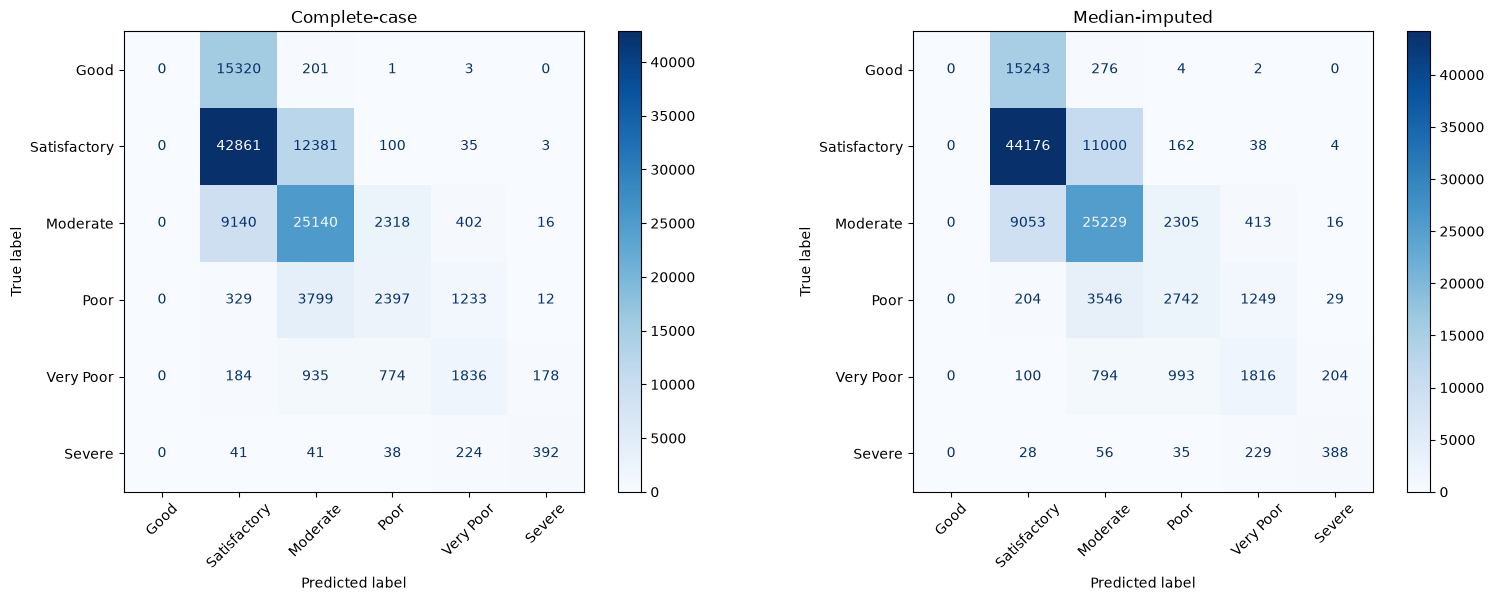

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

aqi_classes = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, actual, predicted, title in [
    (axes[0], y_test_complete, y_pred_complete, "Complete-case"),
    (axes[1], y_test_common, y_pred_imputed_common, "Median-imputed")
]:
    cm = confusion_matrix(
        actual,
        predicted,
        labels=aqi_classes
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=aqi_classes
    ).plot(ax=ax, cmap="Blues", xticks_rotation=45)

    ax.set_title(title)

plt.tight_layout()
plt.show()

In [ ]:
# Match the complete-case training sample size
sample_size = len(X_train_complete)

# Randomly select the same number of imputed training observations
X_train_imputed_reduced = X_train_imputed.sample(
    n=sample_size,
    random_state=42
)

y_train_imputed_reduced = y_train.loc[X_train_imputed_reduced.index]

print("Complete-case training:", len(X_train_complete))
print("Reduced imputed training:", len(X_train_imputed_reduced))
print("Full imputed training:", len(X_train_imputed))

Complete-case training: 144992
Reduced imputed training: 144992
Full imputed training: 372595


In [ ]:
reduced_imputed_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

reduced_imputed_model.fit(
    X_train_imputed_reduced,
    y_train_imputed_reduced
)

y_pred_reduced_imputed = reduced_imputed_model.predict(
    X_test_imputed_common
)

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

reduced_accuracy = accuracy_score(
    y_test_common, y_pred_reduced_imputed
)

reduced_macro_f1 = f1_score(
    y_test_common, y_pred_reduced_imputed,
    average="macro", zero_division=0
)

reduced_weighted_f1 = f1_score(
    y_test_common, y_pred_reduced_imputed,
    average="weighted", zero_division=0
)

print("REDUCED IMPUTED MODEL")
print("Accuracy:", round(reduced_accuracy, 4))
print("Macro F1:", round(reduced_macro_f1, 4))
print("Weighted F1:", round(reduced_weighted_f1, 4))

REDUCED IMPUTED MODEL
Accuracy: 0.614
Macro F1: 0.4578
Weighted F1: 0.5677
